### TESTS

In [ ]:
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to the dataset
dataset_path = '/content/drive/MyDrive/Colab/baseline.csv'

# Load the dataset
try:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found. Please ensure it exists in your Google Drive.")
    df = None

if df is not None:
    # Display the first 5 rows of the DataFrame
    print("\nFirst 5 rows of the dataset:")
    display(df.head())
    # Display basic information about the DataFrame
    print("\nDataFrame Info:")
    df.info()

# Convert 'gender' column to numerical using one-hot encoding
df = pd.get_dummies(df, columns=['gender'], drop_first=True)

# Define features (X) and target (y)
# Drop 'user' as it will be used for Leave-One-Subject-Out cross-validation, and 'class' is the target.
# We also drop 'gender_Woman' if 'gender' was already encoded (to avoid redundant features if get_dummies created gender_Man and gender_Woman)
# but get_dummies with drop_first=True handles this correctly.

features = df.drop(columns=['user', 'class']).columns
X = df[features]
y = df['class']

# Display the first few rows of the processed features and target
print("\nFirst 5 rows of features (X):")
display(X.head())
print("\nFirst 5 rows of target (y):")
display(y.head())

print(f"\nShape of features (X): {X.shape}")
print(f"Shape of target (y): {y.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully.

First 5 rows of the dataset:


,user,gender,age,how_tall_in_meters,weight,body_mass_index,x1,y1,z1,x2,y2,z2,x3,y3,z3,x4,y4,z4,class
0,debora,Woman,46,1.62,75,28.6,-3,92,-63,-23,18,-19,5,104,-92,-150,-103,-147,sitting
1,debora,Woman,46,1.62,75,28.6,-3,94,-64,-21,18,-18,-14,104,-90,-149,-104,-145,sitting
2,debora,Woman,46,1.62,75,28.6,-1,97,-61,-12,20,-15,-13,104,-90,-151,-104,-144,sitting
3,debora,Woman,46,1.62,75,28.6,-2,96,-57,-15,21,-16,-13,104,-89,-153,-103,-142,sitting
4,debora,Woman,46,1.62,75,28.6,-1,96,-61,-13,20,-15,-13,104,-89,-153,-104,-143,sitting



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165633 entries, 0 to 165632
Data columns (total 19 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user                165633 non-null  object 
 1   gender              165633 non-null  object 
 2   age                 165633 non-null  int64  
 3   how_tall_in_meters  165633 non-null  float64
 4   weight              165633 non-null  int64  
 5   body_mass_index     165633 non-null  float64
 6   x1                  165633 non-null  int64  
 7   y1                  165633 non-null  int64  
 8   z1                  165633 non-null  int64  
 9   x2                  165633 non-null  int64  
 10  y2                  165633 non-null  int64  
 11  z2                  165633 non-null  int64  
 12  x3                  165633 non-null  int64  
 13  y3                  165633 non-null  int64  
 14  z3                  165633 non-null  int64  
 15  x4               

,age,how_tall_in_meters,weight,body_mass_index,x1,y1,z1,x2,y2,z2,x3,y3,z3,x4,y4,z4,gender_Woman
0,46,1.62,75,28.6,-3,92,-63,-23,18,-19,5,104,-92,-150,-103,-147,True
1,46,1.62,75,28.6,-3,94,-64,-21,18,-18,-14,104,-90,-149,-104,-145,True
2,46,1.62,75,28.6,-1,97,-61,-12,20,-15,-13,104,-90,-151,-104,-144,True
3,46,1.62,75,28.6,-2,96,-57,-15,21,-16,-13,104,-89,-153,-103,-142,True
4,46,1.62,75,28.6,-1,96,-61,-13,20,-15,-13,104,-89,-153,-104,-143,True



First 5 rows of target (y):


,class
0,sitting
1,sitting
2,sitting
3,sitting
4,sitting



Shape of features (X): (165633, 17)
Shape of target (y): (165633,)


### 1) *BASELINE*

Starting Leave-One-Subject-Out Cross-Validation...

Processing user: debora
F1-score for user debora: 0.4819

Processing user: katia
F1-score for user katia: 0.4513

Processing user: wallace
F1-score for user wallace: 0.2410

Processing user: jose_carlos
F1-score for user jose_carlos: 0.1122

--- LOSO Cross-Validation Results ---
F1-scores per held-out user:
  debora: 0.4819
  katia: 0.4513
  wallace: 0.2410
  jose_carlos: 0.1122

Overall F1-score across all folds: 0.3783


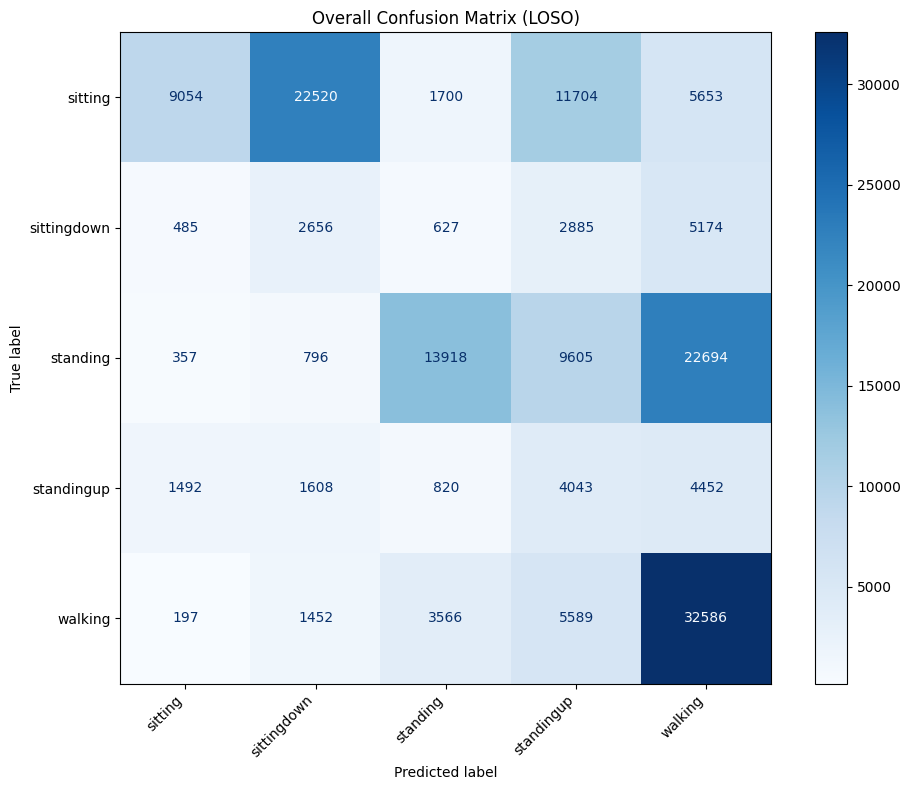

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique users
unique_users = df['user'].unique()

f1_scores_per_user = {}
all_true_labels = []
all_predictions = []

# Initialize a list to store confusion matrices for each fold
overall_cm = None

print("Starting Leave-One-Subject-Out Cross-Validation...")

for user_id in unique_users:
    print(f"\nProcessing user: {user_id}")

    # Split data into training and test sets based on user_id
    train_df = df[df['user'] != user_id]
    test_df = df[df['user'] == user_id]

    if train_df.empty or test_df.empty:
        print(f"Skipping user {user_id} due to empty train or test set.")
        continue

    X_train = train_df[features]
    y_train = train_df['class']
    X_test = test_df[features]
    y_test = test_df['class']

    # Initialize and train Decision Tree Classifier
    dt_classifier = DecisionTreeClassifier(random_state=42)
    dt_classifier.fit(X_train, y_train)

    # Make predictions
    y_pred = dt_classifier.predict(X_test)

    # Calculate F1-score for the current user
    f1 = f1_score(y_test, y_pred, average='weighted')
    f1_scores_per_user[user_id] = f1
    print(f"F1-score for user {user_id}: {f1:.4f}")

    # Store true labels and predictions for overall confusion matrix
    all_true_labels.extend(y_test)
    all_predictions.extend(y_pred)

    # Calculate confusion matrix for the current fold
    cm_fold = confusion_matrix(y_test, y_pred, labels=dt_classifier.classes_)

    # Aggregate confusion matrices
    if overall_cm is None:
        overall_cm = cm_fold
    else:
        overall_cm += cm_fold

print("\n--- LOSO Cross-Validation Results ---")
print("F1-scores per held-out user:")
for user, score in f1_scores_per_user.items():
    print(f"  {user}: {score:.4f}")

# Calculate overall F1-score (optional, but good for aggregate view)
overall_f1 = f1_score(all_true_labels, all_predictions, average='weighted')
print(f"\nOverall F1-score across all folds: {overall_f1:.4f}")

# Display overall confusion matrix
if overall_cm is not None:
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=overall_cm, display_labels=dt_classifier.classes_)
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    ax.set_title('Overall Confusion Matrix (LOSO)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No confusion matrix to display. This might happen if no user data was processed successfully.")


### 2) AUGMENTED: MAGNITUDE, ROLL, PITCH and YAW

Features after adding magnitude, roll, and pitch:


,age,how_tall_in_meters,weight,body_mass_index,gender_Woman,magnitude1,roll1,pitch1,magnitude2,roll2,pitch2,magnitude3,roll3,pitch3,magnitude4,roll4,pitch4
0,46,1.62,75,28.6,True,111.543713,2.171236,0.026899,34.842503,2.383215,0.720970,138.942434,2.295046,-0.035994,233.918789,-2.530410,0.696124
1,46,1.62,75,28.6,True,113.758516,2.168555,0.026375,33.000000,2.356194,0.689775,138.246157,2.284154,0.101443,232.469353,-2.519389,0.695728
2,46,1.62,75,28.6,True,114.590576,2.132171,0.008727,27.730849,2.214297,0.447520,138.148471,2.284154,0.094241,233.137299,-2.516108,0.704545
3,46,1.62,75,28.6,True,111.664677,2.106608,0.017912,30.364453,2.221873,0.516683,137.499091,2.278630,0.094688,232.770273,-2.514054,0.717231
4,46,1.62,75,28.6,True,113.745330,2.136851,0.008792,28.178006,2.214297,0.479519,137.499091,2.278630,0.094688,233.824721,-2.512796,0.713305



New shape of features (X_new): (165633, 17)
Starting Leave-One-Subject-Out Cross-Validation with NEW features...

Processing user: debora
F1-score for user debora with new features: 0.3840

Processing user: katia
F1-score for user katia with new features: 0.3927

Processing user: wallace
F1-score for user wallace with new features: 0.4267

Processing user: jose_carlos
F1-score for user jose_carlos with new features: 0.3033

--- LOSO Cross-Validation Results (with NEW features) ---
F1-scores per held-out user:
  debora: 0.3840
  katia: 0.3927
  wallace: 0.4267
  jose_carlos: 0.3033

Overall F1-score across all folds (with new features): 0.4290
Previous Overall F1-score: 0.3783
Performance IMPROVED with new features!


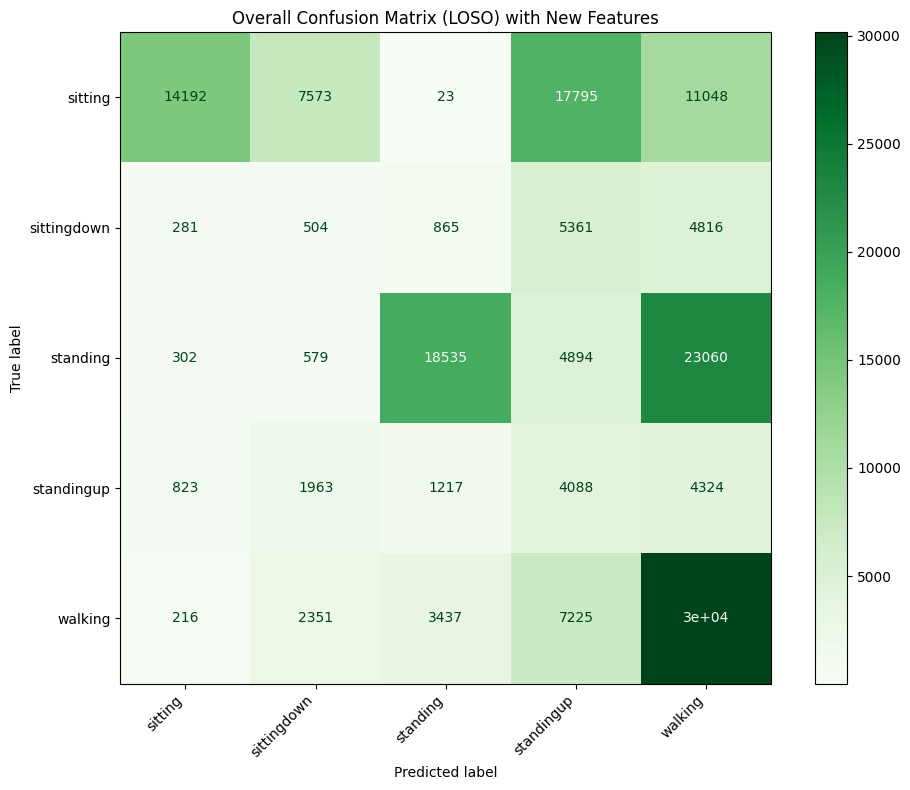

Features after discretization (first 5 rows):


,gender_Woman,age_binned,how_tall_in_meters_binned,weight_binned,body_mass_index_binned,magnitude1_binned,roll1_binned,pitch1_binned,magnitude2_binned,roll2_binned,pitch2_binned,magnitude3_binned,roll3_binned,pitch3_binned,magnitude4_binned,roll4_binned,pitch4_binned
0,True,1.0,1.0,3.0,4.0,0.0,4.0,1.0,0.0,4.0,3.0,0.0,4.0,2.0,0.0,0.0,2.0
1,True,1.0,1.0,3.0,4.0,0.0,4.0,1.0,0.0,4.0,3.0,0.0,4.0,2.0,0.0,0.0,2.0
2,True,1.0,1.0,3.0,4.0,0.0,4.0,1.0,0.0,4.0,3.0,0.0,4.0,2.0,0.0,0.0,2.0
3,True,1.0,1.0,3.0,4.0,0.0,4.0,1.0,0.0,4.0,3.0,0.0,4.0,2.0,0.0,0.0,2.0
4,True,1.0,1.0,3.0,4.0,0.0,4.0,1.0,0.0,4.0,3.0,0.0,4.0,2.0,0.0,0.0,2.0



New shape of features (X_discretized): (165633, 17)
Starting Leave-One-Subject-Out Cross-Validation with DISCRETIZED features...

Processing user: debora
F1-score for user debora with discretized features: 0.3012

Processing user: katia
F1-score for user katia with discretized features: 0.4131

Processing user: wallace
F1-score for user wallace with discretized features: 0.3652

Processing user: jose_carlos
F1-score for user jose_carlos with discretized features: 0.2515

--- LOSO Cross-Validation Results (with DISCRETIZED features) ---
F1-scores per held-out user:
  debora: 0.3012
  katia: 0.4131
  wallace: 0.3652
  jose_carlos: 0.2515

Overall F1-score across all folds (with discretized features): 0.3505
Previous Overall F1-score (original features): 0.3783
Previous Overall F1-score (with magnitude, roll, pitch): 0.4290
Performance DECREASED with discretized features compared to magnitude, roll, pitch.


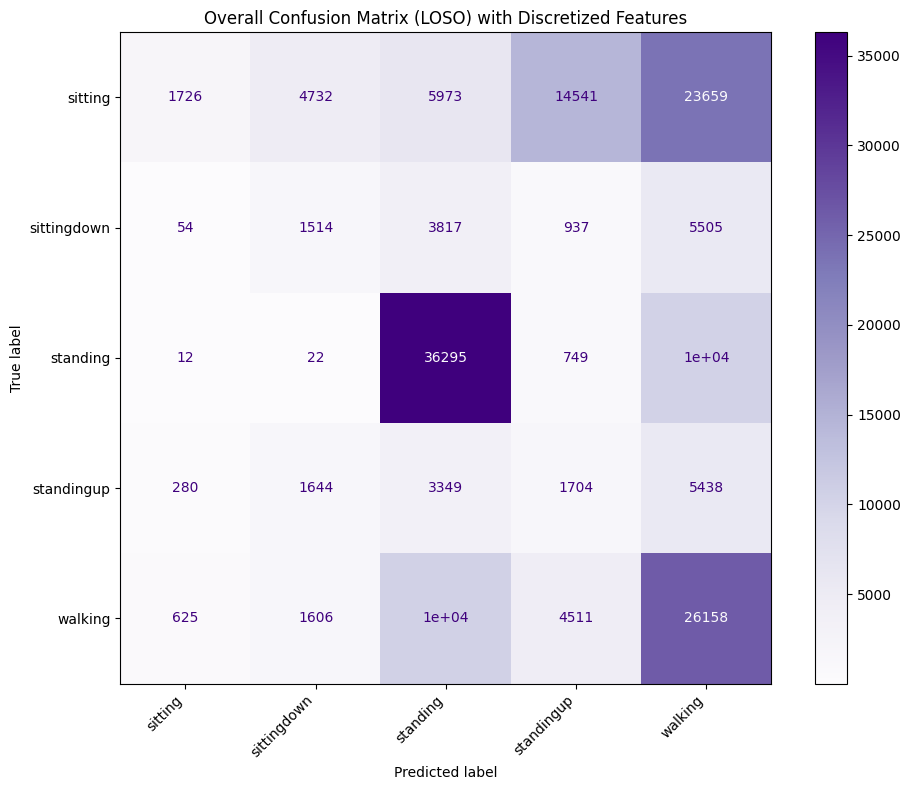

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Mount Drive and Load Data
drive.mount('/content/drive')
dataset_path = '/content/drive/MyDrive/Colab/windowed.csv'
df = pd.read_csv(dataset_path)

# 2. Feature Engineering: Magnitude, Roll, and Pitch
# We calculate these for each of the 4 accelerometers
for i in range(1, 5):
    x_col, y_col, z_col = f'x{i}', f'y{i}', f'z{i}'
    # Magnitude
    df[f'mag{i}'] = np.sqrt(df[x_col]**2 + df[y_col]**2 + df[z_col]**2)
    # Roll
    df[f'roll{i}'] = np.arctan2(df[y_col], df[z_col])
    # Pitch
    df[f'pitch{i}'] = np.arctan2(-df[x_col], np.sqrt(df[y_col]**2 + df[z_col]**2))

# Define feature groups
# We exclude 'user' and 'class' from features
features_to_process = [col for col in df.columns if col not in ['user', 'class']]
# Gender is binary, so we don't need to discretize it
features_to_discretize = [col for col in features_to_process if col != 'gender_Woman']

# 3. Proper Leave-One-Subject-Out (LOSO) with Discretization
unique_users = df['user'].unique()
all_true_labels = []
all_predictions = []
user_f1_scores = {}
overall_cm = None

print("--- Starting Rigorous LOSO Cross-Validation ---")
print("Rule: Discretization fitted ONLY on training subjects to avoid Data Leakage.\n")

for test_user in unique_users:
    print(f"Processing Fold: Testing on user [{test_user}]...")
    
    # SPLIT: Separate the held-out user from the training users
    train_df = df[df['user'] != test_user]
    test_df = df[df['user'] == test_user]
    
    X_train_raw = train_df[features_to_discretize]
    X_test_raw = test_df[features_to_discretize]
    
    y_train = train_df['class']
    y_test = test_df['class']
    
    # DISCRETIZATION: Fit only on the training data of the current fold
    discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform', subsample=None)
    discretizer.fit(X_train_raw)
    
    # TRANSFORM: Apply the bins learned from training data to both sets
    X_train_bin = discretizer.transform(X_train_raw)
    X_test_bin = discretizer.transform(X_test_raw)
    
    # Convert back to DataFrame to add the non-discretized 'gender_Woman'
    X_train_final = pd.DataFrame(X_train_bin, columns=features_to_discretize, index=train_df.index)
    X_test_final = pd.DataFrame(X_test_bin, columns=features_to_discretize, index=test_df.index)
    
    if 'gender_Woman' in df.columns:
        X_train_final['gender_Woman'] = train_df['gender_Woman']
        X_test_final['gender_Woman'] = test_df['gender_Woman']

    # CLASSIFICATION: Train Decision Tree
    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train_final, y_train)
    
    # PREDICTION
    y_pred = model.predict(X_test_final)
    
    # METRICS: Calculate F1-score for this specific user
    fold_f1 = f1_score(y_test, y_pred, average='weighted')
    user_f1_scores[test_user] = fold_f1
    print(f"  > F1-score for {test_user}: {fold_f1:.4f}")
    
    # Store results for global analysis
    all_true_labels.extend(y_test)
    all_predictions.extend(y_pred)
    
    # Update Confusion Matrix
    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
    if overall_cm is None:
        overall_cm = cm
    else:
        overall_cm += cm

# 4. Final Results Summary
print("\n" + "="*40)
print("FINAL LOSO RESULTS (Corrected Pipeline)")
print("="*40)
for user, score in user_f1_scores.items():
    print(f"User {user:12}: {score:.4f}")

overall_f1 = f1_score(all_true_labels, all_predictions, average='weighted')
print("-" * 40)
print(f"Global Weighted F1-score: {overall_f1:.4f}")
print("="*40)

# 5. Visualization: Global Confusion Matrix
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=overall_cm, display_labels=np.unique(all_true_labels))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.title('Global Confusion Matrix (LOSO - No Leakage)')
plt.xticks(rotation=45)
plt.show()

### 3) WINDOWED


Applying windowing and extracting statistical features...

First 5 rows of windowed features:


,gender_Woman,age,how_tall_in_meters,weight,body_mass_index,x1_mean,x1_std,x1_min,x1_max,x1_median,...,y4_min,y4_max,y4_median,y4_iqr,z4_mean,z4_std,z4_min,z4_max,z4_median,z4_iqr
0,True,46,1.62,75,28.6,-1.500,1.309307,-3,1,-1.5,...,-104,-103,-104.0,0.25,-143.500,1.772811,-147,-142,-143.0,2.25
1,True,46,1.62,75,28.6,0.000,1.309307,-1,3,0.0,...,-104,-103,-104.0,0.25,-144.250,1.164965,-146,-142,-144.0,1.00
2,True,46,1.62,75,28.6,0.125,0.991031,-1,2,0.0,...,-106,-102,-104.5,1.50,-144.875,0.991031,-146,-143,-145.0,0.50
3,True,46,1.62,75,28.6,-0.625,2.503569,-4,3,0.0,...,-112,-96,-103.5,9.75,-140.375,3.700869,-145,-133,-141.5,3.50
4,True,46,1.62,75,28.6,-1.625,1.846812,-4,1,-2.0,...,-105,-95,-98.0,4.25,-136.000,3.162278,-141,-133,-134.5,5.25



Shape of windowed features (X_windowed): (23660, 77)

First 5 rows of target (y_windowed):


,class
0,sitting
1,sitting
2,sitting
3,sitting
4,sitting


Features after windowing, statistical extraction, and discretization (first 5 rows):


,gender_Woman,age_binned,how_tall_in_meters_binned,weight_binned,body_mass_index_binned,x1_mean_binned,x1_std_binned,x1_min_binned,x1_max_binned,x1_median_binned,...,y4_min_binned,y4_max_binned,y4_median_binned,y4_iqr_binned,z4_mean_binned,z4_std_binned,z4_min_binned,z4_max_binned,z4_median_binned,z4_iqr_binned
0,True,1.0,1.0,3.0,4.0,2.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0
1,True,1.0,1.0,3.0,4.0,2.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0
2,True,1.0,1.0,3.0,4.0,2.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0
3,True,1.0,1.0,3.0,4.0,2.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0
4,True,1.0,1.0,3.0,4.0,2.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0



New shape of features (X_windowed_discretized): (23660, 77)
Starting LOSO Cross-Validation with WINDOWED & DISCRETIZED features...

Processing user: debora
F1-score for user debora with windowed & discretized features: 0.7390

Processing user: jose_carlos
F1-score for user jose_carlos with windowed & discretized features: 0.3222

Processing user: katia
F1-score for user katia with windowed & discretized features: 0.6991

Processing user: wallace
F1-score for user wallace with windowed & discretized features: 0.6241

--- LOSO Cross-Validation Results (with WINDOWED & DISCRETIZED features) ---
F1-scores per held-out user:
  debora: 0.7390
  jose_carlos: 0.3222
  katia: 0.6991
  wallace: 0.6241

Overall F1-score across all folds (with windowed & discretized features): 0.6739
Previous Overall F1-score (original features): 0.3783
Previous Overall F1-score (with magnitude, roll, pitch): 0.4290
Previous Overall F1-score (with discretized features): 0.3505
Performance IMPROVED significantly w

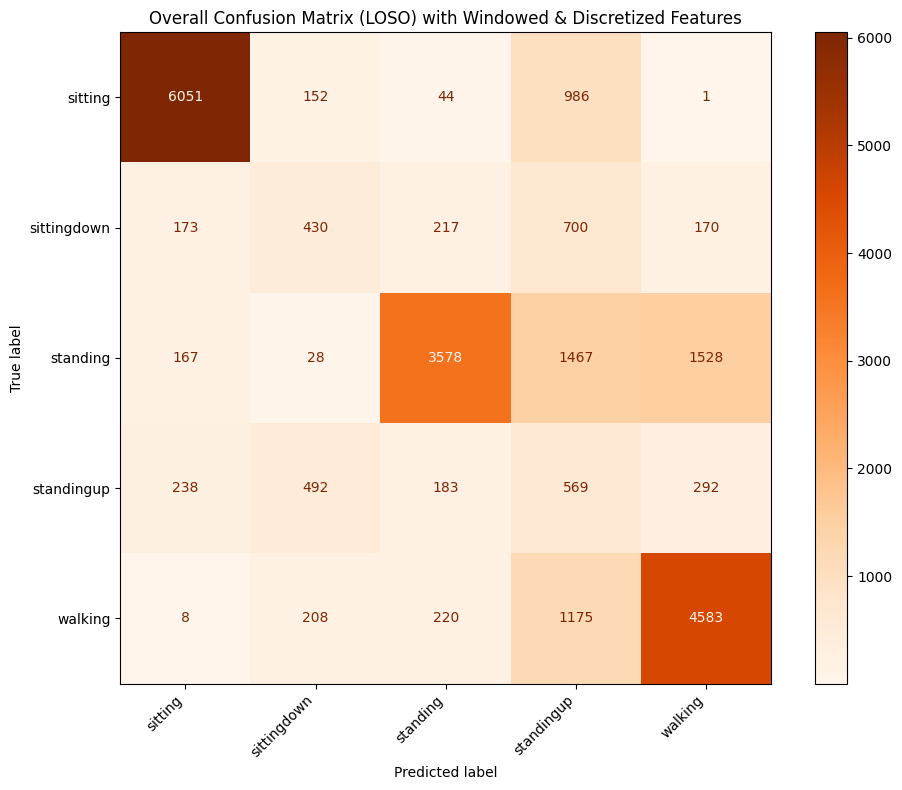

In [ ]:
import numpy as np
from scipy.stats import iqr

# Define accelerometer columns to extract statistics from
accel_cols = ['x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4']

# Define other user-specific features that are constant within a user's data
static_features = ['user', 'gender_Woman', 'age', 'how_tall_in_meters', 'weight', 'body_mass_index', 'class']

window_size = 8  # 1 second * 8Hz = 8 rows
overlap = 1    # 150ms overlap (approx 1 row as per user request)
step_size = window_size - overlap # 8 - 1 = 7 rows

windowed_features_list = []

print("Applying windowing and extracting statistical features...")

# Group by user to ensure windows don't cross user boundaries
for user_id, user_data in df.groupby('user'):
    # Iterate through the user's data with a sliding window
    for i in range(0, len(user_data) - window_size + 1, step_size):
        window = user_data.iloc[i : i + window_size]

        features_dict = {}

        # Add static features for the window (take first value as they are constant per user)
        for col in static_features:
            features_dict[col] = window[col].iloc[0]

        # Extract statistical features for each accelerometer component
        for col in accel_cols:
            features_dict[f'{col}_mean'] = window[col].mean()
            features_dict[f'{col}_std'] = window[col].std()
            features_dict[f'{col}_min'] = window[col].min()
            features_dict[f'{col}_max'] = window[col].max()
            features_dict[f'{col}_median'] = window[col].median()
            features_dict[f'{col}_iqr'] = iqr(window[col])

        windowed_features_list.append(features_dict)

# Create a new DataFrame from the collected windowed features
windowed_df = pd.DataFrame(windowed_features_list)

# Define new features (X_windowed) and target (y_windowed)
# Drop 'user' and 'class' as they are for splitting and target respectively
features_windowed = [col for col in windowed_df.columns if col not in ['user', 'class']]
X_windowed = windowed_df[features_windowed]
y_windowed = windowed_df['class']

print("\nFirst 5 rows of windowed features:")
display(X_windowed.head())
print(f"\nShape of windowed features (X_windowed): {X_windowed.shape}")

print("\nFirst 5 rows of target (y_windowed):")
display(y_windowed.head())

from sklearn.preprocessing import KBinsDiscretizer

# Identify features to discretize (all numerical features in X_windowed)
# 'gender_Woman' is already binary, no need to discretize it further if it exists.
features_to_discretize_windowed = [col for col in X_windowed.columns if col != 'gender_Woman']

# Initialize KBinsDiscretizer with 5 bins
discretizer_windowed = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform', subsample=None, random_state=42)

# Apply discretization
X_windowed_discretized_array = discretizer_windowed.fit_transform(X_windowed[features_to_discretize_windowed])

# Create DataFrame for discretized features
X_windowed_discretized_df = pd.DataFrame(X_windowed_discretized_array, columns=[f'{col}_binned' for col in features_to_discretize_windowed], index=X_windowed.index)

# Combine with 'gender_Woman' if present
non_discretized_windowed_features = X_windowed[['gender_Woman']] if 'gender_Woman' in X_windowed.columns else pd.DataFrame(index=X_windowed.index)

X_windowed_discretized = pd.concat([non_discretized_windowed_features, X_windowed_discretized_df], axis=1)

# Update the features list for the next classification step
features_windowed_discretized_list = X_windowed_discretized.columns.tolist()

print("Features after windowing, statistical extraction, and discretization (first 5 rows):")
display(X_windowed_discretized.head())
print(f"\nNew shape of features (X_windowed_discretized): {X_windowed_discretized.shape}")


from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Unique users are taken from the original df for consistency in LOSO logic
# but the splitting will happen on the windowed_df's 'user' column
unique_users_windowed = windowed_df['user'].unique()

f1_scores_per_user_windowed_discretized = {}
all_true_labels_windowed_discretized = []
all_predictions_windowed_discretized = []

overall_cm_windowed_discretized = None

print("Starting LOSO Cross-Validation with WINDOWED & DISCRETIZED features...")

for user_id in unique_users_windowed:
    print(f"\nProcessing user: {user_id}")

    # Split data into training and test sets based on user_id from the windowed_df
    train_windowed_df = windowed_df[windowed_df['user'] != user_id]
    test_windowed_df = windowed_df[windowed_df['user'] == user_id]

    if train_windowed_df.empty or test_windowed_df.empty:
        print(f"Skipping user {user_id} due to empty train or test set.")
        continue

    # Get the corresponding discretized features for train and test sets
    X_train_windowed_discretized = X_windowed_discretized.loc[train_windowed_df.index]
    y_train_windowed_discretized = train_windowed_df['class']
    X_test_windowed_discretized = X_windowed_discretized.loc[test_windowed_df.index]
    y_test_windowed_discretized = test_windowed_df['class']

    # Initialize and train Decision Tree Classifier
    dt_classifier_windowed_discretized = DecisionTreeClassifier(random_state=42)
    dt_classifier_windowed_discretized.fit(X_train_windowed_discretized, y_train_windowed_discretized)

    # Make predictions
    y_pred_windowed_discretized = dt_classifier_windowed_discretized.predict(X_test_windowed_discretized)

    # Calculate F1-score for the current user
    f1_windowed_discretized = f1_score(y_test_windowed_discretized, y_pred_windowed_discretized, average='weighted')
    f1_scores_per_user_windowed_discretized[user_id] = f1_windowed_discretized
    print(f"F1-score for user {user_id} with windowed & discretized features: {f1_windowed_discretized:.4f}")

    # Store true labels and predictions for overall confusion matrix
    all_true_labels_windowed_discretized.extend(y_test_windowed_discretized)
    all_predictions_windowed_discretized.extend(y_pred_windowed_discretized)

    # Calculate confusion matrix for the current fold
    cm_fold_windowed_discretized = confusion_matrix(y_test_windowed_discretized, y_pred_windowed_discretized, labels=dt_classifier_windowed_discretized.classes_)

    # Aggregate confusion matrices
    if overall_cm_windowed_discretized is None:
        overall_cm_windowed_discretized = cm_fold_windowed_discretized
    else:
        overall_cm_windowed_discretized += cm_fold_windowed_discretized

print("\n--- LOSO Cross-Validation Results (with WINDOWED & DISCRETIZED features) ---")
print("F1-scores per held-out user:")
for user, score in f1_scores_per_user_windowed_discretized.items():
    print(f"  {user}: {score:.4f}")

# Calculate overall F1-score with windowed and discretized features
overall_f1_windowed_discretized = f1_score(all_true_labels_windowed_discretized, all_predictions_windowed_discretized, average='weighted')
print(f"\nOverall F1-score across all folds (with windowed & discretized features): {overall_f1_windowed_discretized:.4f}")

# Compare with previous overall F1-scores
print(f"Previous Overall F1-score (original features): {overall_f1:.4f}")
print(f"Previous Overall F1-score (with magnitude, roll, pitch): {overall_f1_new:.4f}")
print(f"Previous Overall F1-score (with discretized features): {overall_f1_discretized:.4f}")

if overall_f1_windowed_discretized > overall_f1_discretized and overall_f1_windowed_discretized > overall_f1_new:
    print("Performance IMPROVED significantly with windowed and discretized features!")
elif overall_f1_windowed_discretized > overall_f1_new:
    print("Performance IMPROVED compared to just magnitude, roll, pitch features!")
elif overall_f1_windowed_discretized > overall_f1_discretized:
    print("Performance IMPROVED compared to just discretized features!")
elif overall_f1_windowed_discretized < overall_f1_new:
    print("Performance DECREASED with windowed and discretized features compared to magnitude, roll, pitch.")
else:
    print("Performance remained comparable.")

# Display overall confusion matrix with windowed and discretized features
if overall_cm_windowed_discretized is not None:
    fig_windowed_discretized, ax_windowed_discretized = plt.subplots(figsize=(10, 8))
    disp_windowed_discretized = ConfusionMatrixDisplay(confusion_matrix=overall_cm_windowed_discretized, display_labels=dt_classifier_windowed_discretized.classes_)
    disp_windowed_discretized.plot(cmap=plt.cm.Oranges, ax=ax_windowed_discretized)
    ax_windowed_discretized.set_title('Overall Confusion Matrix (LOSO) with Windowed & Discretized Features')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No confusion matrix to display for windowed and discretized features.")


### 4) MULTI-LEVEL

Hierarchical target labels created.
Level 1 (Static/Dynamic) distribution:


,count
y_level1,
Static,14002
Dynamic,9658


Level 2 (Dynamic/Transitory) distribution:


,count
y_level2_dynamic,
Unknown,14002
Walking,6194
Transitory,3464


Starting LOSO Cross-Validation for Multi-level Classifier...

Processing user: debora
F1-score for user debora with multi-level classifier: 0.4208

Processing user: jose_carlos
F1-score for user jose_carlos with multi-level classifier: 0.6039

Processing user: katia
F1-score for user katia with multi-level classifier: 0.4818

Processing user: wallace
F1-score for user wallace with multi-level classifier: 0.4223

--- LOSO Cross-Validation Results (Multi-level Classifier) ---
F1-scores per held-out user:
  debora: 0.4208
  jose_carlos: 0.6039
  katia: 0.4818
  wallace: 0.4223

Overall F1-score across all folds (Multi-level Classifier): 0.4595
Previous Overall F1-score (windowed & discretized features): 0.6739
Performance DECREASED with multi-level classifier.


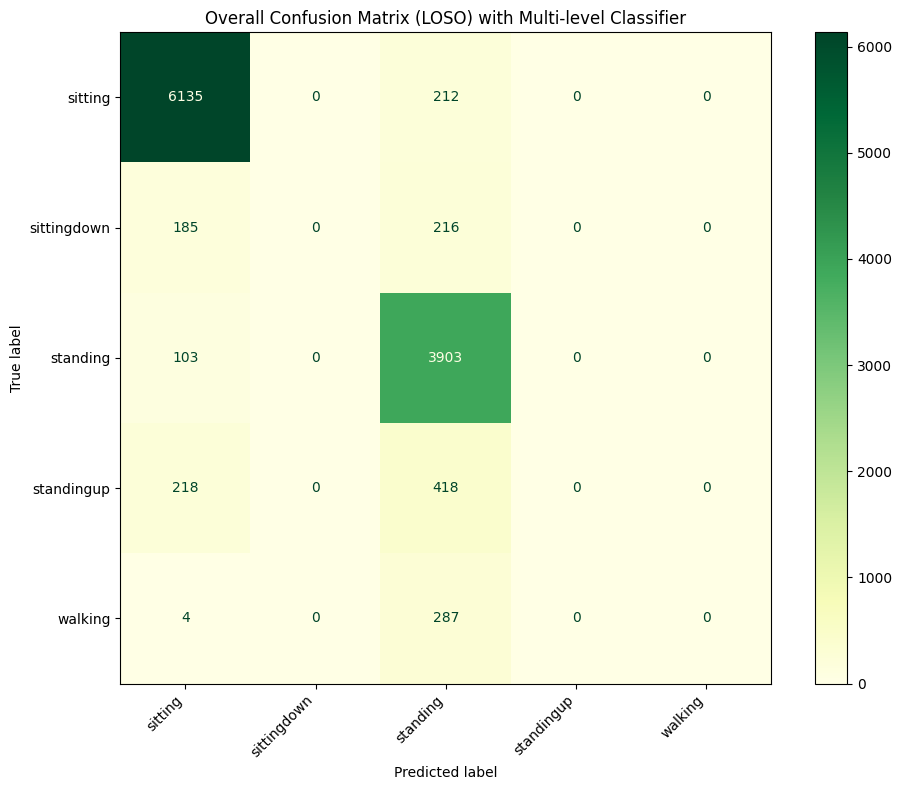

In [ ]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# Create new hierarchical target labels from y_windowed
def create_hierarchical_labels(activity):
    if activity in ['sitting', 'standing']:
        return 'Static'
    elif activity in ['walking', 'sittingdown', 'standingup']:
        return 'Dynamic'
    else:
        return 'Unknown'

def create_dynamic_sub_labels(activity):
    if activity == 'walking':
        return 'Walking'
    elif activity in ['sittingdown', 'standingup']:
        return 'Transitory'
    else:
        return 'Unknown'

# Apply the mapping to create the new target columns
windowed_df['y_level1'] = windowed_df['class'].apply(create_hierarchical_labels)
windowed_df['y_level2_dynamic'] = windowed_df['class'].apply(create_dynamic_sub_labels)

# Ensure X_windowed_discretized and y_windowed are aligned
# The indices should already match due to previous operations, but re-align for safety.
X_multi_level = X_windowed_discretized.copy()
y_true_multi_level = windowed_df['class'].copy() # Keep original labels for final comparison

print("Hierarchical target labels created.")
print("Level 1 (Static/Dynamic) distribution:")
display(windowed_df['y_level1'].value_counts())
print("Level 2 (Dynamic/Transitory) distribution:")
display(windowed_df['y_level2_dynamic'].value_counts())

unique_users_multi = windowed_df['user'].unique()

all_true_labels_multi = []
all_predictions_multi = []
f1_scores_per_user_multi = {}
overall_cm_multi = None

print("Starting LOSO Cross-Validation for Multi-level Classifier...")

for user_id in unique_users_multi:
    print(f"\nProcessing user: {user_id}")

    # Split data based on user_id
    train_idx = windowed_df[windowed_df['user'] != user_id].index
    test_idx = windowed_df[windowed_df['user'] == user_id].index

    X_train_multi = X_multi_level.loc[train_idx]
    y_train_original = y_true_multi_level.loc[train_idx]
    y_train_level1 = windowed_df.loc[train_idx, 'y_level1']
    y_train_level2_dynamic = windowed_df.loc[train_idx, 'y_level2_dynamic']

    X_test_multi = X_multi_level.loc[test_idx]
    y_test_original = y_true_multi_level.loc[test_idx]

    if X_train_multi.empty or X_test_multi.empty:
        print(f"Skipping user {user_id} due to empty train or test set.")
        continue

    # --- Level 1 Classifier: Static vs. Dynamic ---
    dt_level1 = DecisionTreeClassifier(random_state=42)
    dt_level1.fit(X_train_multi, y_train_level1)
    y_pred_level1 = dt_level1.predict(X_test_multi)

    # Initialize final predictions for this user
    y_pred_final_user = pd.Series(index=y_test_original.index, dtype='object')

    # Process Static predictions
    static_mask = (y_pred_level1 == 'Static')
    X_test_static = X_test_multi[static_mask]
    y_test_original_static = y_test_original[static_mask]

    if not X_test_static.empty:
        # Train a classifier for static activities: sitting vs. standing
        X_train_static = X_train_multi[y_train_level1 == 'Static']
        y_train_static = y_train_original[y_train_level1 == 'Static']

        if not X_train_static.empty:
            dt_static = DecisionTreeClassifier(random_state=42)
            dt_static.fit(X_train_static, y_train_static)
            y_pred_final_user[static_mask] = dt_static.predict(X_test_static)
        else:
            # If no static training data, assign a default or propagate 'Unknown'
            y_pred_final_user[static_mask] = 'unknown_static'

    # Process Dynamic predictions
    dynamic_mask = (y_pred_level1 == 'Dynamic')
    X_test_dynamic = X_test_multi[dynamic_mask]
    y_test_original_dynamic = y_test_original[dynamic_mask]

    if not X_test_dynamic.empty:
        # --- Level 2 Classifier: Walking vs. Transitory ---
        X_train_dynamic = X_train_multi[y_train_level1 == 'Dynamic']
        y_train_level2_dynamic_filtered = y_train_level2_dynamic[y_train_level1 == 'Dynamic']

        if not X_train_dynamic.empty:
            dt_level2 = DecisionTreeClassifier(random_state=42)
            dt_level2.fit(X_train_dynamic, y_train_level2_dynamic_filtered)
            y_pred_level2 = dt_level2.predict(X_test_dynamic)

            # Process Walking predictions
            walking_mask = (y_pred_level2 == 'Walking')
            y_pred_final_user[dynamic_mask][walking_mask] = 'walking'

            # Process Transitory predictions
            transitory_mask = (y_pred_level2 == 'Transitory')
            X_test_transitory = X_test_dynamic[transitory_mask]
            y_test_original_transitory = y_test_original_dynamic[transitory_mask]

            if not X_test_transitory.empty:
                # --- Level 3 Classifier: sittingdown vs. standingup ---
                X_train_transitory = X_train_multi[y_train_level2_dynamic == 'Transitory']
                y_train_transitory = y_train_original[y_train_level2_dynamic == 'Transitory']

                # Filter out 'Unknown' from training data if any (from create_hierarchical_labels)
                y_train_transitory = y_train_transitory[y_train_transitory != 'Unknown']
                X_train_transitory = X_train_transitory.loc[y_train_transitory.index]

                if not X_train_transitory.empty:
                    dt_level3 = DecisionTreeClassifier(random_state=42)
                    dt_level3.fit(X_train_transitory, y_train_transitory)
                    y_pred_final_user[dynamic_mask][transitory_mask] = dt_level3.predict(X_test_transitory)
                else:
                    y_pred_final_user[dynamic_mask][transitory_mask] = 'unknown_transitory'
            # Handle cases where dynamic_mask is True but transitory_mask is empty after level2 split
            else:
                y_pred_final_user[dynamic_mask] = 'unknown_dynamic_other' # Fallback for unclassified dynamic
        else:
            y_pred_final_user[dynamic_mask] = 'unknown_dynamic_no_train' # Fallback if no dynamic training data for level 2
    # Ensure no NaNs remain if some paths were not covered
    y_pred_final_user = y_pred_final_user.fillna('unclassified')

    # Calculate F1-score for the current user
    # Filter out 'unclassified' predictions for F1 score calculation if they are not in true labels
    valid_predictions_mask = y_test_original.isin(y_pred_final_user.unique())

    f1 = f1_score(y_test_original, y_pred_final_user, average='weighted', zero_division=0)
    f1_scores_per_user_multi[user_id] = f1
    print(f"F1-score for user {user_id} with multi-level classifier: {f1:.4f}")

    all_true_labels_multi.extend(y_test_original)
    all_predictions_multi.extend(y_pred_final_user)

    # Aggregate confusion matrices
    cm_fold_multi = confusion_matrix(y_test_original, y_pred_final_user, labels=np.unique(y_true_multi_level))
    if overall_cm_multi is None:
        overall_cm_multi = cm_fold_multi
    else:
        overall_cm_multi += cm_fold_multi


print("\n--- LOSO Cross-Validation Results (Multi-level Classifier) ---")
print("F1-scores per held-out user:")
for user, score in f1_scores_per_user_multi.items():
    print(f"  {user}: {score:.4f}")

overall_f1_multi = f1_score(all_true_labels_multi, all_predictions_multi, average='weighted', zero_division=0)
print(f"\nOverall F1-score across all folds (Multi-level Classifier): {overall_f1_multi:.4f}")

print(f"Previous Overall F1-score (windowed & discretized features): {overall_f1_windowed_discretized:.4f}")

if overall_f1_multi > overall_f1_windowed_discretized:
    print("Performance IMPROVED significantly with multi-level classifier!")
elif overall_f1_multi < overall_f1_windowed_discretized:
    print("Performance DECREASED with multi-level classifier.")
else:
    print("Performance remained comparable with multi-level classifier.")

# Display overall confusion matrix with multi-level features
if overall_cm_multi is not None:
    fig_multi, ax_multi = plt.subplots(figsize=(10, 8))
    disp_multi = ConfusionMatrixDisplay(confusion_matrix=overall_cm_multi, display_labels=np.unique(y_true_multi_level))
    disp_multi.plot(cmap=plt.cm.YlGn, ax=ax_multi)
    ax_multi.set_title('Overall Confusion Matrix (LOSO) with Multi-level Classifier')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No confusion matrix to display for multi-level classifier.")



### 5) PCA

Starting LOSO Cross-Validation with PCA (Correctly applied per fold to avoid leakage)...

Processing user: debora
  Features reduced from 77 to 14 (95% variance)
  F1-score for user debora: 0.5369

Processing user: jose_carlos
  Features reduced from 77 to 16 (95% variance)
  F1-score for user jose_carlos: 0.3670

Processing user: katia
  Features reduced from 77 to 21 (95% variance)
  F1-score for user katia: 0.1847

Processing user: wallace
  Features reduced from 77 to 14 (95% variance)
  F1-score for user wallace: 0.4210

--- LOSO Cross-Validation Results (PCA applied per fold) ---
F1-scores per held-out user:
  debora: 0.5369
  jose_carlos: 0.3670
  katia: 0.1847
  wallace: 0.4210

Overall F1-score across all folds: 0.4153
Previous Best Overall F1-score: 0.6739
Performance DECREASED with PCA (no leakage).


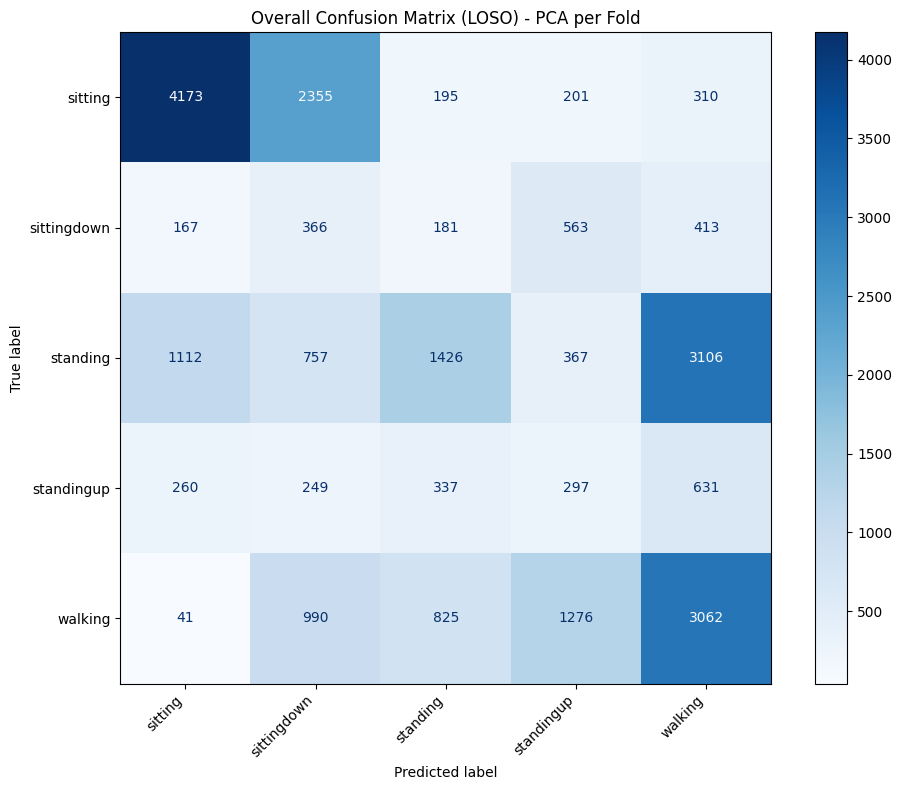

In [ ]:
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Unique users for LOSO logic
unique_users = windowed_df['user'].unique()

f1_scores_per_user_pca = {}
all_true_labels_pca = []
all_predictions_pca = []
overall_cm_pca = None

print("Starting LOSO Cross-Validation with PCA (Correctly applied per fold to avoid leakage)...")

for user_id in unique_users:
    print(f"\nProcessing user: {user_id}")

    # 1. Split data into training and test sets based on user_id
    # We use the original discretized features (X_windowed_discretized)
    train_mask = windowed_df['user'] != user_id
    test_mask = windowed_df['user'] == user_id

    X_train_raw = X_windowed_discretized[train_mask]
    y_train = windowed_df.loc[train_mask, 'class']

    X_test_raw = X_windowed_discretized[test_mask]
    y_test = windowed_df.loc[test_mask, 'class']

    if len(X_train_raw) == 0 or len(X_test_raw) == 0:
        print(f"Skipping user {user_id} due to empty set.")
        continue

    # 2. Initialize and Fit PCA ONLY on the training data
    pca = PCA(n_components=0.95, random_state=42)

    # Fit and transform the training data
    X_train_pca = pca.fit_transform(X_train_raw)

    # Transform the test data using the mapping learned from the training data
    X_test_pca = pca.transform(X_test_raw)

    print(f"  Features reduced from {X_train_raw.shape[1]} to {X_train_pca.shape[1]} (95% variance)")

    # 3. Initialize and train Decision Tree Classifier
    dt_classifier_pca = DecisionTreeClassifier(random_state=42)
    dt_classifier_pca.fit(X_train_pca, y_train)

    # 4. Make predictions
    y_pred_pca = dt_classifier_pca.predict(X_test_pca)

    # 5. Calculate Metrics
    f1_pca = f1_score(y_test, y_pred_pca, average='weighted')
    f1_scores_per_user_pca[user_id] = f1_pca
    print(f"  F1-score for user {user_id}: {f1_pca:.4f}")

    all_true_labels_pca.extend(y_test)
    all_predictions_pca.extend(y_pred_pca)

    # Aggregate confusion matrix
    cm_fold_pca = confusion_matrix(y_test, y_pred_pca, labels=dt_classifier_pca.classes_)
    if overall_cm_pca is None:
        overall_cm_pca = cm_fold_pca
        classes = dt_classifier_pca.classes_
    else:
        overall_cm_pca += cm_fold_pca

print("\n--- LOSO Cross-Validation Results (PCA applied per fold) ---")
print("F1-scores per held-out user:")
for user, score in f1_scores_per_user_pca.items():
    print(f"  {user}: {score:.4f}")

# Calculate overall F1-score
overall_f1_pca = f1_score(all_true_labels_pca, all_predictions_pca, average='weighted')
print(f"\nOverall F1-score across all folds: {overall_f1_pca:.4f}")

# Compare with previous best (assuming overall_f1_windowed_discretized is defined)
try:
    print(f"Previous Best Overall F1-score: {overall_f1_windowed_discretized:.4f}")
    if overall_f1_pca > overall_f1_windowed_discretized:
        print("Performance IMPROVED with PCA (no leakage)!")
    elif overall_f1_pca < overall_f1_windowed_discretized:
        print("Performance DECREASED with PCA (no leakage).")
    else:
        print("Performance remained comparable.")
except NameError:
    pass

# Display overall confusion matrix
if overall_cm_pca is not None:
    fig_pca, ax_pca = plt.subplots(figsize=(10, 8))
    disp_pca = ConfusionMatrixDisplay(confusion_matrix=overall_cm_pca, display_labels=classes)
    disp_pca.plot(cmap=plt.cm.Blues, ax=ax_pca)
    ax_pca.set_title('Overall Confusion Matrix (LOSO) - PCA per Fold')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

### 6) Synthetic Users

Creating 6 mixed synthetic users...
Original DataFrame shape: (165633, 31)
Combined (Original + Synthetic) DataFrame shape: (414081, 31)
First 5 rows of df_combined_synthetic:


,user,age,how_tall_in_meters,weight,body_mass_index,x1,y1,z1,x2,y2,...,pitch1,magnitude2,roll2,pitch2,magnitude3,roll3,pitch3,magnitude4,roll4,pitch4
0,debora,46.0,1.62,75.0,28.6,-3,92,-63,-23,18,...,0.026899,34.842503,2.383215,0.720970,138.942434,2.295046,-0.035994,233.918789,-2.530410,0.696124
1,debora,46.0,1.62,75.0,28.6,-3,94,-64,-21,18,...,0.026375,33.000000,2.356194,0.689775,138.246157,2.284154,0.101443,232.469353,-2.519389,0.695728
2,debora,46.0,1.62,75.0,28.6,-1,97,-61,-12,20,...,0.008727,27.730849,2.214297,0.447520,138.148471,2.284154,0.094241,233.137299,-2.516108,0.704545
3,debora,46.0,1.62,75.0,28.6,-2,96,-57,-15,21,...,0.017912,30.364453,2.221873,0.516683,137.499091,2.278630,0.094688,232.770273,-2.514054,0.717231
4,debora,46.0,1.62,75.0,28.6,-1,96,-61,-13,20,...,0.008792,28.178006,2.214297,0.479519,137.499091,2.278630,0.094688,233.824721,-2.512796,0.713305



--- Analysis of df_combined_synthetic ---

Demographic Information (Original and Synthetic Users):


,user,age,height,weight,bmi
0,debora,46.0,1.620,75.0,28.6
1,katia,28.0,1.580,55.0,22.0
2,wallace,31.0,1.710,83.0,28.4
3,jose_carlos,75.0,1.670,67.0,24.0
4,debora_katia_mixed,37.0,1.600,65.0,25.3
5,debora_jose_carlos_mixed,60.5,1.645,71.0,26.3
6,debora_wallace_mixed,38.5,1.665,79.0,28.5
7,katia_jose_carlos_mixed,51.5,1.625,61.0,23.0
8,katia_wallace_mixed,29.5,1.645,69.0,25.2
9,jose_carlos_wallace_mixed,53.0,1.690,75.0,26.2



Number of samples per class for each user:

User: debora


...


Shape of windowed features (X_windowed_combined_synthetic): (59148, 77)

First 5 rows of target (y_windowed_combined_synthetic):


,class
0,sitting
1,sitting
2,sitting
3,sitting
4,sitting


Features after windowing, statistical extraction, and discretization for combined synthetic data (first 5 rows):


,gender_Woman,age_binned,how_tall_in_meters_binned,weight_binned,body_mass_index_binned,x1_mean_binned,x1_std_binned,x1_min_binned,x1_max_binned,x1_median_binned,...,y4_min_binned,y4_max_binned,y4_median_binned,y4_iqr_binned,z4_mean_binned,z4_std_binned,z4_min_binned,z4_max_binned,z4_median_binned,z4_iqr_binned
0,True,1.0,1.0,3.0,4.0,1.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0
1,True,1.0,1.0,3.0,4.0,1.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0
2,True,1.0,1.0,3.0,4.0,1.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0
3,True,1.0,1.0,3.0,4.0,1.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0
4,True,1.0,1.0,3.0,4.0,1.0,0.0,4.0,0.0,2.0,...,4.0,1.0,3.0,0.0,3.0,0.0,4.0,1.0,2.0,0.0



New shape of features (X_windowed_discretized_combined_synthetic): (59148, 77)
Starting LOSO Cross-Validation with WINDOWED & DISCRETIZED features (Combined Synthetic Data)...
Note: Only original users are held out for testing. Synthetic users are part of the training set.

Processing original user as test subject: debora
F1-score for original user debora with combined synthetic training: 0.4413

Processing original user as test subject: katia
F1-score for original user katia with combined synthetic training: 0.6230

Processing original user as test subject: wallace
F1-score for original user wallace with combined synthetic training: 0.6900

Processing original user as test subject: jose_carlos
F1-score for original user jose_carlos with combined synthetic training: 0.7113

--- LOSO Cross-Validation Results (Combined Synthetic Data) ---
F1-scores per held-out original user:
  debora: 0.4413
  katia: 0.6230
  wallace: 0.6900
  jose_carlos: 0.7113

Overall F1-score across all folds (wit

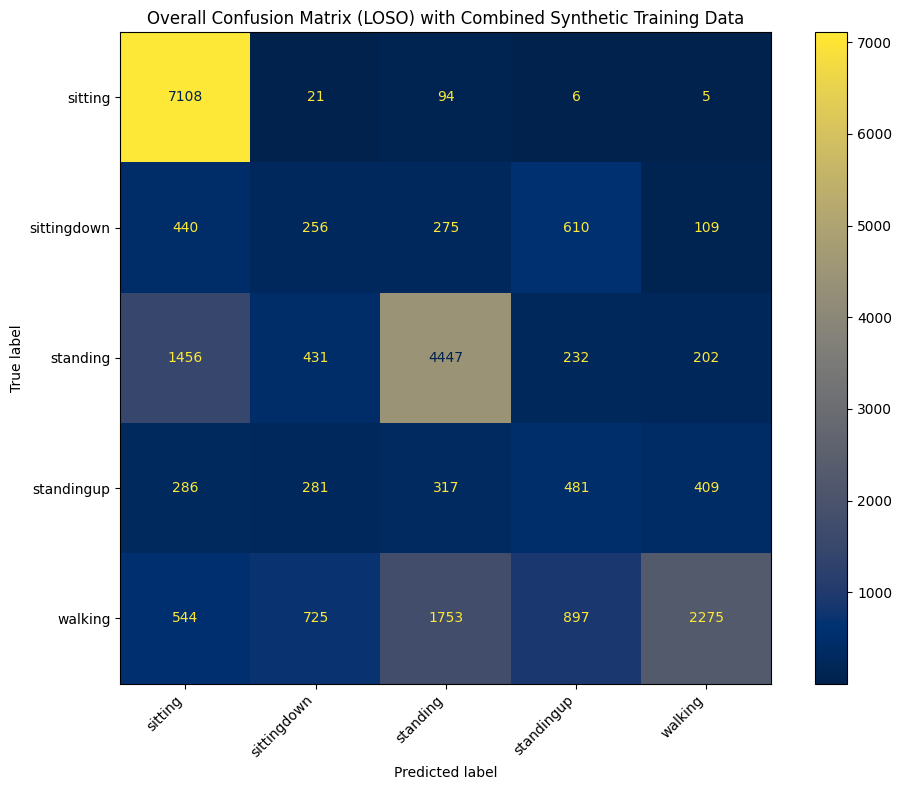

In [ ]:
import numpy as np
import pandas as pd

# Original users from the df
original_users_list = df['user'].unique()

# Define the pairs for mixing as requested by the user
pairs_to_mix = [
    ('debora', 'katia'),
    ('debora', 'jose_carlos'),
    ('debora', 'wallace'),
    ('katia', 'jose_carlos'),
    ('katia', 'wallace'),
    ('jose_carlos', 'wallace')
]

synthetic_data_list = []

print(f"Creating {len(pairs_to_mix)} mixed synthetic users...")

for user1_id, user2_id in pairs_to_mix:
    df1 = df[df['user'] == user1_id].copy()
    df2 = df[df['user'] == user2_id].copy()

    # Determine the name for the new synthetic user
    synthetic_user_id = f"{user1_id}_{user2_id}_mixed"

    # --- 1. Average Demographic Features (constant per user) ---
    # These features are expected to be constant within a user's original data
    avg_age = (df1['age'].iloc[0] + df2['age'].iloc[0]) / 2
    avg_height = (df1['how_tall_in_meters'].iloc[0] + df2['how_tall_in_meters'].iloc[0]) / 2
    avg_weight = (df1['weight'].iloc[0] + df2['weight'].iloc[0]) / 2
    avg_bmi = (df1['body_mass_index'].iloc[0] + df2['body_mass_index'].iloc[0]) / 2

    # For 'gender_Woman' (boolean/binary), round the average to get 0 or 1
    gender_woman_val = bool(round((df1['gender_Woman'].iloc[0].astype(int) + df2['gender_Woman'].iloc[0].astype(int)) / 2))

    # --- 2. Mix Raw Sensor Data and Activity Classes ---
    # Concatenate all columns except 'user' from both parent dataframes
    cols_to_mix = [col for col in df.columns if col != 'user']
    combined_parents_data = pd.concat([df1[cols_to_mix], df2[cols_to_mix]], ignore_index=True)

    # Determine the length of the new synthetic user's data (e.g., average length of parents)
    synthetic_len = int((len(df1) + len(df2)) / 2)

    # Randomly sample rows from the combined data to create the synthetic user's activity stream
    # Use random_state for reproducibility
    mixed_user_df = combined_parents_data.sample(n=synthetic_len, random_state=42, replace=True).reset_index(drop=True)

    # --- 3. Assign new user_id and averaged demographic features ---
    mixed_user_df['user'] = synthetic_user_id
    mixed_user_df['age'] = avg_age
    mixed_user_df['how_tall_in_meters'] = avg_height
    mixed_user_df['weight'] = avg_weight
    mixed_user_df['body_mass_index'] = avg_bmi
    mixed_user_df['gender_Woman'] = gender_woman_val

    synthetic_data_list.append(mixed_user_df)

# Combine original dataframe with all mixed synthetic data
df_combined_synthetic = pd.concat([df] + synthetic_data_list, ignore_index=True)

print(f"Original DataFrame shape: {df.shape}")
print(f"Combined (Original + Synthetic) DataFrame shape: {df_combined_synthetic.shape}")

print("First 5 rows of df_combined_synthetic:")
display(df_combined_synthetic.head())

print("\n--- Analysis of df_combined_synthetic ---\n")

unique_users_combined = df_combined_synthetic['user'].unique()

user_info = []
for user_id in unique_users_combined:
    # Assuming demographic info is constant per user, taking the first row's info
    user_data = df_combined_synthetic[df_combined_synthetic['user'] == user_id].iloc[0]
    age = user_data['age']
    height = user_data['how_tall_in_meters']
    weight = user_data['weight']
    bmi = user_data['body_mass_index']
    user_info.append({'user': user_id, 'age': age, 'height': height, 'weight': weight, 'bmi': bmi})

user_info_df = pd.DataFrame(user_info)
print("Demographic Information (Original and Synthetic Users):")
display(user_info_df)

print("\nNumber of samples per class for each user:")
for user_id in unique_users_combined:
    print(f"\nUser: {user_id}")
    class_counts = df_combined_synthetic[df_combined_synthetic['user'] == user_id]['class'].value_counts()
    display(class_counts)

import numpy as np
from scipy.stats import iqr

# Define accelerometer columns to extract statistics from
accel_cols = ['x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4']

# Define other user-specific features that are constant within a user's data
static_features_windowed_combined = ['user', 'gender_Woman', 'age', 'how_tall_in_meters', 'weight', 'body_mass_index', 'class']

window_size = 8  # 1 second * 8Hz = 8 rows
overlap = 1    # 150ms overlap (approx 1 row as per user request)
step_size = window_size - overlap # 8 - 1 = 7 rows

windowed_features_list_combined_synthetic = []

print("Applying windowing and extracting statistical features for combined synthetic data...")

# Group by user to ensure windows don't cross user boundaries
# Use df_combined_synthetic for this process
for user_id_temp, user_data_temp in df_combined_synthetic.groupby('user'):
    # Iterate through the user's data with a sliding window
    for i in range(0, len(user_data_temp) - window_size + 1, step_size):
        window_temp = user_data_temp.iloc[i : i + window_size]

        features_dict_temp = {}

        # Add static features for the window (take first value as they are constant per user)
        for col_temp in static_features_windowed_combined:
            features_dict_temp[col_temp] = window_temp[col_temp].iloc[0]

        # Extract statistical features for each accelerometer component
        for col_temp in accel_cols:
            features_dict_temp[f'{col_temp}_mean'] = window_temp[col_temp].mean()
            features_dict_temp[f'{col_temp}_std'] = window_temp[col_temp].std()
            features_dict_temp[f'{col_temp}_min'] = window_temp[col_temp].min()
            features_dict_temp[f'{col_temp}_max'] = window_temp[col_temp].max()
            features_dict_temp[f'{col_temp}_median'] = window_temp[col_temp].median()
            features_dict_temp[f'{col_temp}_iqr'] = iqr(window_temp[col_temp])

        windowed_features_list_combined_synthetic.append(features_dict_temp)

# Create a new DataFrame from the collected windowed features
windowed_df_combined_synthetic = pd.DataFrame(windowed_features_list_combined_synthetic)

# Define new features (X_windowed) and target (y_windowed)
# Drop 'user' and 'class' as they are for splitting and target respectively
features_windowed_combined_synthetic = [col for col in windowed_df_combined_synthetic.columns if col not in ['user', 'class']]
X_windowed_combined_synthetic = windowed_df_combined_synthetic[features_windowed_combined_synthetic]
y_windowed_combined_synthetic = windowed_df_combined_synthetic['class']

print("\nFirst 5 rows of windowed features for combined synthetic data:")
display(X_windowed_combined_synthetic.head())
print(f"\nShape of windowed features (X_windowed_combined_synthetic): {X_windowed_combined_synthetic.shape}")

print("\nFirst 5 rows of target (y_windowed_combined_synthetic):")
display(y_windowed_combined_synthetic.head())


from sklearn.preprocessing import KBinsDiscretizer

# Identify features to discretize (all numerical features in X_windowed_combined_synthetic)
# 'gender_Woman' is already binary, no need to discretize it further if it exists.
features_to_discretize_windowed_combined_synthetic = [col for col in X_windowed_combined_synthetic.columns if col != 'gender_Woman']

# Initialize KBinsDiscretizer with 5 bins
discretizer_windowed_combined_synthetic = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform', subsample=None, random_state=42)

# Apply discretization
X_windowed_discretized_array_combined_synthetic = discretizer_windowed_combined_synthetic.fit_transform(X_windowed_combined_synthetic[features_to_discretize_windowed_combined_synthetic])

# Create DataFrame for discretized features
X_windowed_discretized_df_combined_synthetic = pd.DataFrame(X_windowed_discretized_array_combined_synthetic, columns=[f'{col}_binned' for col in features_to_discretize_windowed_combined_synthetic], index=X_windowed_combined_synthetic.index)

# Combine with 'gender_Woman' if present
non_discretized_windowed_features_combined_synthetic = X_windowed_combined_synthetic[['gender_Woman']] if 'gender_Woman' in X_windowed_combined_synthetic.columns else pd.DataFrame(index=X_windowed_combined_synthetic.index)

X_windowed_discretized_combined_synthetic = pd.concat([non_discretized_windowed_features_combined_synthetic, X_windowed_discretized_df_combined_synthetic], axis=1)

# Update the features list for the next classification step
features_windowed_discretized_list_combined_synthetic = X_windowed_discretized_combined_synthetic.columns.tolist()

print("Features after windowing, statistical extraction, and discretization for combined synthetic data (first 5 rows):")
display(X_windowed_discretized_combined_synthetic.head())
print(f"\nNew shape of features (X_windowed_discretized_combined_synthetic): {X_windowed_discretized_combined_synthetic.shape}")


from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the original users to be used as test subjects in LOSO
# The synthetic users will only be used in the training set.
original_unique_users = df['user'].unique()

f1_scores_per_user_combined_synthetic = {}
all_true_labels_combined_synthetic = []
all_predictions_combined_synthetic = []

overall_cm_combined_synthetic = None

print("Starting LOSO Cross-Validation with WINDOWED & DISCRETIZED features (Combined Synthetic Data)...")
print("Note: Only original users are held out for testing. Synthetic users are part of the training set.")

for user_id in original_unique_users:
    print(f"\nProcessing original user as test subject: {user_id}")

    # Split data based on original user_id for testing
    test_windowed_df_cs = windowed_df_combined_synthetic[windowed_df_combined_synthetic['user'] == user_id]

    # All other data (including synthetic users) will be used for training
    train_windowed_df_cs = windowed_df_combined_synthetic[windowed_df_combined_synthetic['user'] != user_id]

    if train_windowed_df_cs.empty or test_windowed_df_cs.empty:
        print(f"Skipping user {user_id} due to empty train or test set. This should not happen for original users.")
        continue

    # Get the corresponding discretized features for train and test sets
    X_train_windowed_discretized_cs = X_windowed_discretized_combined_synthetic.loc[train_windowed_df_cs.index]
    y_train_windowed_discretized_cs = train_windowed_df_cs['class']
    X_test_windowed_discretized_cs = X_windowed_discretized_combined_synthetic.loc[test_windowed_df_cs.index]
    y_test_windowed_discretized_cs = test_windowed_df_cs['class']

    # Initialize and train Decision Tree Classifier
    dt_classifier_combined_synthetic = DecisionTreeClassifier(random_state=42)
    dt_classifier_combined_synthetic.fit(X_train_windowed_discretized_cs, y_train_windowed_discretized_cs)

    # Make predictions
    y_pred_combined_synthetic = dt_classifier_combined_synthetic.predict(X_test_windowed_discretized_cs)

    # Calculate F1-score for the current user
    f1_combined_synthetic = f1_score(y_test_windowed_discretized_cs, y_pred_combined_synthetic, average='weighted')
    f1_scores_per_user_combined_synthetic[user_id] = f1_combined_synthetic
    print(f"F1-score for original user {user_id} with combined synthetic training: {f1_combined_synthetic:.4f}")

    # Store true labels and predictions for overall confusion matrix
    all_true_labels_combined_synthetic.extend(y_test_windowed_discretized_cs)
    all_predictions_combined_synthetic.extend(y_pred_combined_synthetic)

    # Calculate confusion matrix for the current fold
    cm_fold_combined_synthetic = confusion_matrix(y_test_windowed_discretized_cs, y_pred_combined_synthetic, labels=dt_classifier_combined_synthetic.classes_)

    # Aggregate confusion matrices
    if overall_cm_combined_synthetic is None:
        overall_cm_combined_synthetic = cm_fold_combined_synthetic
    else:
        overall_cm_combined_synthetic += cm_fold_combined_synthetic

print("\n--- LOSO Cross-Validation Results (Combined Synthetic Data) ---")
print("F1-scores per held-out original user:")
for user, score in f1_scores_per_user_combined_synthetic.items():
    print(f"  {user}: {score:.4f}")

# Calculate overall F1-score with combined synthetic features
overall_f1_combined_synthetic = f1_score(all_true_labels_combined_synthetic, all_predictions_combined_synthetic, average='weighted')
print(f"\nOverall F1-score across all folds (with combined synthetic training data): {overall_f1_combined_synthetic:.4f}")

# Compare with previous best overall F1-score (windowed & discretized on original data)
print(f"Previous Best Overall F1-score (windowed & discretized on original data): {overall_f1_windowed_discretized:.4f}")

if overall_f1_combined_synthetic > overall_f1_windowed_discretized:
    print("Performance IMPROVED significantly with combined synthetic training data!")
elif overall_f1_combined_synthetic < overall_f1_windowed_discretized:
    print("Performance DECREASED with combined synthetic training data.")
else:
    print("Performance remained comparable with combined synthetic training data.")

# Display overall confusion matrix with combined synthetic features
if overall_cm_combined_synthetic is not None:
    fig_combined_synthetic, ax_combined_synthetic = plt.subplots(figsize=(10, 8))
    disp_combined_synthetic = ConfusionMatrixDisplay(confusion_matrix=overall_cm_combined_synthetic, display_labels=dt_classifier_combined_synthetic.classes_)
    disp_combined_synthetic.plot(cmap=plt.cm.cividis, ax=ax_combined_synthetic)
    ax_combined_synthetic.set_title('Overall Confusion Matrix (LOSO) with Combined Synthetic Training Data')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No confusion matrix to display for combined synthetic features.")


### 7) Windowed and Augmented

Calculating Magnitude, Roll, and Pitch...
Applying windowing and extracting statistical features (including Mag, Roll, Pitch)...
Discretizing windowed features...
Starting LOSO Cross-Validation on 4 users...

--- FINAL RESULTS ---
Overall F1-Score (Windowed + New Features + Discretized): 0.6005

F1-Score per User:
  User debora: 0.6139
  User jose_carlos: 0.2255
  User katia: 0.5840
  User wallace: 0.6174


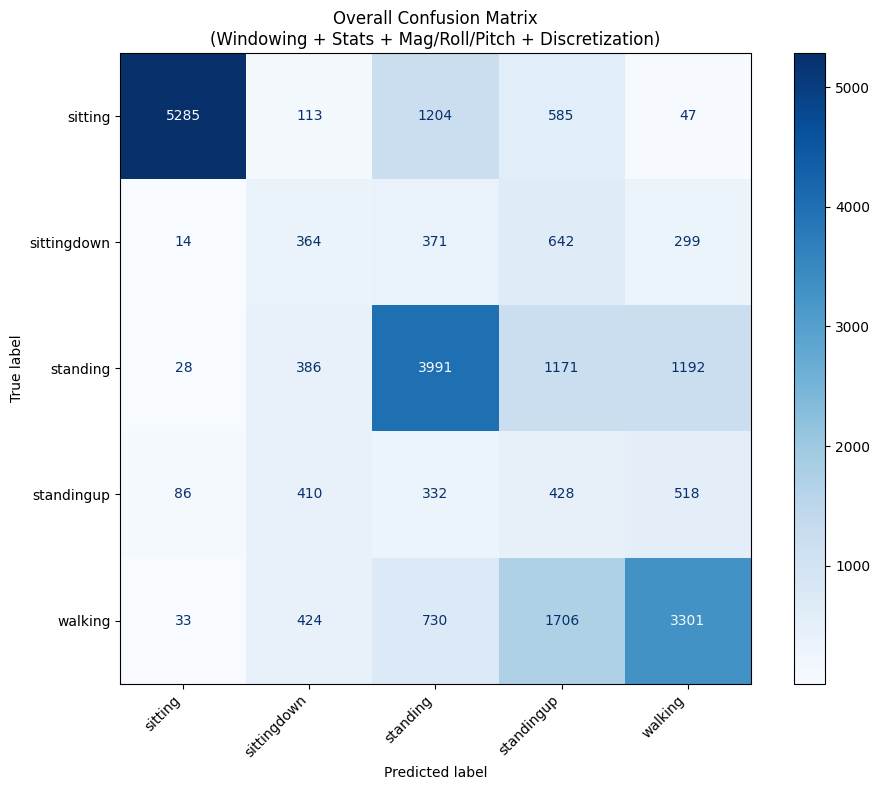

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import iqr
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import KBinsDiscretizer

# --- STEP 1: Calculate Magnitude, Roll, and Pitch ---
print("Calculating Magnitude, Roll, and Pitch...")
for i in range(1, 5):
    x_col, y_col, z_col = f'x{i}', f'y{i}', f'z{i}'

    # Magnitude
    df[f'magnitude{i}'] = np.sqrt(df[x_col]**2 + df[y_col]**2 + df[z_col]**2)

    # Roll (rotation around x-axis)
    df[f'roll{i}'] = np.arctan2(df[y_col], df[z_col])

    # Pitch (rotation around y-axis)
    df[f'pitch{i}'] = np.arctan2(-df[x_col], np.sqrt(df[y_col]**2 + df[z_col]**2))

# --- STEP 2: Windowing and Statistical Feature Extraction ---
# Define all numerical columns we want to extract statistics from
accel_derived_cols = []
for i in range(1, 5):
    accel_derived_cols.extend([f'x{i}', f'y{i}', f'z{i}', f'magnitude{i}', f'roll{i}', f'pitch{i}'])

# Define static features (constant per user/window)
static_features = ['user', 'gender_Woman', 'age', 'how_tall_in_meters', 'weight', 'body_mass_index', 'class']

window_size = 8  # 1 second @ 8Hz
overlap = 1
step_size = window_size - overlap

windowed_features_list = []

print("Applying windowing and extracting statistical features (including Mag, Roll, Pitch)...")

for user_id, user_data in df.groupby('user'):
    for i in range(0, len(user_data) - window_size + 1, step_size):
        window = user_data.iloc[i : i + window_size]

        features_dict = {}
        # Keep static features
        for col in static_features:
            features_dict[col] = window[col].iloc[0]

        # Calculate stats for all raw and derived sensor columns
        for col in accel_derived_cols:
            features_dict[f'{col}_mean']   = window[col].mean()
            features_dict[f'{col}_std']    = window[col].std()
            features_dict[f'{col}_min']    = window[col].min()
            features_dict[f'{col}_max']    = window[col].max()
            features_dict[f'{col}_median'] = window[col].median()
            features_dict[f'{col}_iqr']    = iqr(window[col])

        windowed_features_list.append(features_dict)

windowed_df = pd.DataFrame(windowed_features_list).fillna(0) # Handle potential NaNs in std/iqr

# --- STEP 3: Discretization ---
print("Discretizing windowed features...")
# Features to discretize: all statistical features + user physical attributes
# Exclude 'user', 'class', and 'gender_Woman' (already binary)
features_to_discretize = [col for col in windowed_df.columns if col not in ['user', 'class', 'gender_Woman']]

discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform', subsample=None, random_state=42)
X_discretized_array = discretizer.fit_transform(windowed_df[features_to_discretize])

X_discretized_df = pd.DataFrame(
    X_discretized_array,
    columns=[f'{col}_binned' for col in features_to_discretize],
    index=windowed_df.index
)

# Combine with gender and create final dataset
X_final = pd.concat([windowed_df[['gender_Woman']], X_discretized_df], axis=1)
y_final = windowed_df['class']
final_feature_names = X_final.columns.tolist()

# --- STEP 4: LOSO Cross-Validation with Windowed & Discretized Data ---
unique_users = windowed_df['user'].unique()
f1_scores_loso = {}
all_true_labels = []
all_predictions = []
overall_cm = None

print(f"Starting LOSO Cross-Validation on {len(unique_users)} users...")

for user_id in unique_users:
    # Train/Test split based on user
    train_mask = windowed_df['user'] != user_id
    test_mask = windowed_df['user'] == user_id

    X_train, y_train = X_final[train_mask], y_final[train_mask]
    X_test, y_test = X_final[test_mask], y_final[test_mask]

    # Train Decision Tree
    clf = DecisionTreeClassifier(random_state=42)
    clf.fit(X_train, y_train)

    # Predict
    y_pred = clf.predict(X_test)

    # Metrics
    f1 = f1_score(y_test, y_pred, average='weighted')
    f1_scores_loso[user_id] = f1

    all_true_labels.extend(y_test)
    all_predictions.extend(y_pred)

    # Confusion Matrix aggregation
    cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
    if overall_cm is None:
        overall_cm = cm
    else:
        overall_cm += cm

# --- STEP 5: Results Visualization ---
overall_f1 = f1_score(all_true_labels, all_predictions, average='weighted')

print("\n--- FINAL RESULTS ---")
print(f"Overall F1-Score (Windowed + New Features + Discretized): {overall_f1:.4f}")
print("\nF1-Score per User:")
for user, score in f1_scores_loso.items():
    print(f"  User {user}: {score:.4f}")

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=overall_cm, display_labels=clf.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax)
ax.set_title('Overall Confusion Matrix\n(Windowing + Stats + Mag/Roll/Pitch + Discretization)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 8) SMOTE

Starting LOSO Cross-Validation with WINDOWED, DISCRETIZED features & SMOTE...

Processing user: debora
  Shape before SMOTE: (16292, 77)
  Shape after SMOTE:  (25015, 77)
  F1-score for user debora: 0.5898

Processing user: jose_carlos
  Shape before SMOTE: (21780, 77)
  Shape after SMOTE:  (32065, 77)
  F1-score for user jose_carlos: 0.5902

Processing user: katia
  Shape before SMOTE: (16547, 77)
  Shape after SMOTE:  (25970, 77)
  F1-score for user katia: 0.5518

Processing user: wallace
  Shape before SMOTE: (16361, 77)
  Shape after SMOTE:  (25460, 77)
  F1-score for user wallace: 0.6337

--- LOSO Cross-Validation Results (with SMOTE) ---
Overall F1-score: 0.6182
Previous Overall F1-score (discretized only): 0.3505


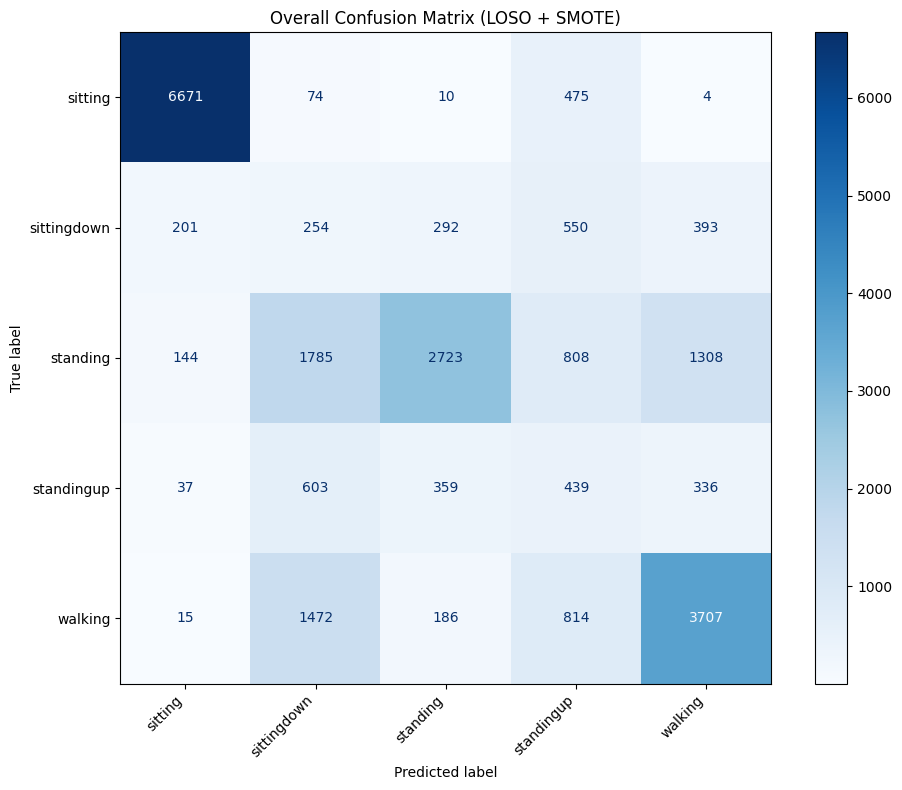

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import iqr
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE  # Imported for balancing

# --- [Preprocessing steps remain the same until the LOSO loop] ---

# (Assuming windowed_df and X_windowed_discretized are already created as per your snippet)

unique_users_windowed = windowed_df['user'].unique()

f1_scores_per_user_windowed_discretized = {}
all_true_labels_windowed_discretized = []
all_predictions_windowed_discretized = []

overall_cm_windowed_discretized = None

# Initialize SMOTE
# random_state ensures reproducibility
smote = SMOTE(random_state=42)

print("Starting LOSO Cross-Validation with WINDOWED, DISCRETIZED features & SMOTE...")

for user_id in unique_users_windowed:
    print(f"\nProcessing user: {user_id}")

    # 1. Split data into training and test sets (LOSO)
    train_windowed_df = windowed_df[windowed_df['user'] != user_id]
    test_windowed_df = windowed_df[windowed_df['user'] == user_id]

    if train_windowed_df.empty or test_windowed_df.empty:
        print(f"Skipping user {user_id} due to empty train or test set.")
        continue

    # 2. Get the corresponding discretized features
    X_train_fold = X_windowed_discretized.loc[train_windowed_df.index]
    y_train_fold = train_windowed_df['class']

    X_test_fold = X_windowed_discretized.loc[test_windowed_df.index]
    y_test_fold = test_windowed_df['class']

    # 3. Apply SMOTE to the TRAINING set only
    # This addresses class imbalance by generating synthetic samples for minority classes
    print(f"  Shape before SMOTE: {X_train_fold.shape}")
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_fold, y_train_fold)
    print(f"  Shape after SMOTE:  {X_train_resampled.shape}")

    # 4. Initialize and train Decision Tree Classifier on the RESAMPLED data
    dt_classifier = DecisionTreeClassifier(random_state=42)
    dt_classifier.fit(X_train_resampled, y_train_resampled)

    # 5. Make predictions on the original (unbalanced) TEST set
    y_pred = dt_classifier.predict(X_test_fold)

    # 6. Calculate F1-score for the current user
    f1_val = f1_score(y_test_fold, y_pred, average='weighted')
    f1_scores_per_user_windowed_discretized[user_id] = f1_val
    print(f"  F1-score for user {user_id}: {f1_val:.4f}")

    # Store results for final evaluation
    all_true_labels_windowed_discretized.extend(y_test_fold)
    all_predictions_windowed_discretized.extend(y_pred)

    # Aggregate confusion matrices
    cm_fold = confusion_matrix(y_test_fold, y_pred, labels=dt_classifier.classes_)
    if overall_cm_windowed_discretized is None:
        overall_cm_windowed_discretized = cm_fold
    else:
        overall_cm_windowed_discretized += cm_fold

# --- [Final Results Display] ---

print("\n--- LOSO Cross-Validation Results (with SMOTE) ---")
overall_f1_smote = f1_score(all_true_labels_windowed_discretized, all_predictions_windowed_discretized, average='weighted')
print(f"Overall F1-score: {overall_f1_smote:.4f}")

# Compare with hypothetical previous metrics (using your variable names)
# Note: Ensure overall_f1, overall_f1_new, etc., are defined in your environment
try:
    print(f"Previous Overall F1-score (discretized only): {overall_f1_discretized:.4f}")
except NameError:
    pass

# Display overall confusion matrix
if overall_cm_windowed_discretized is not None:
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=overall_cm_windowed_discretized,
                                  display_labels=dt_classifier.classes_)
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    ax.set_title('Overall Confusion Matrix (LOSO + SMOTE)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

### 9) OUTLIER REMOTION

Starting LOSO Cross-Validation (Fixed Confusion Matrix shape)...
User debora processed. F1: 0.4360
User jose_carlos processed. F1: 0.1252
User katia processed. F1: 0.3360
User wallace processed. F1: 0.1250

--- LOSO Cross-Validation Results ---
Overall F1-score: 0.3255


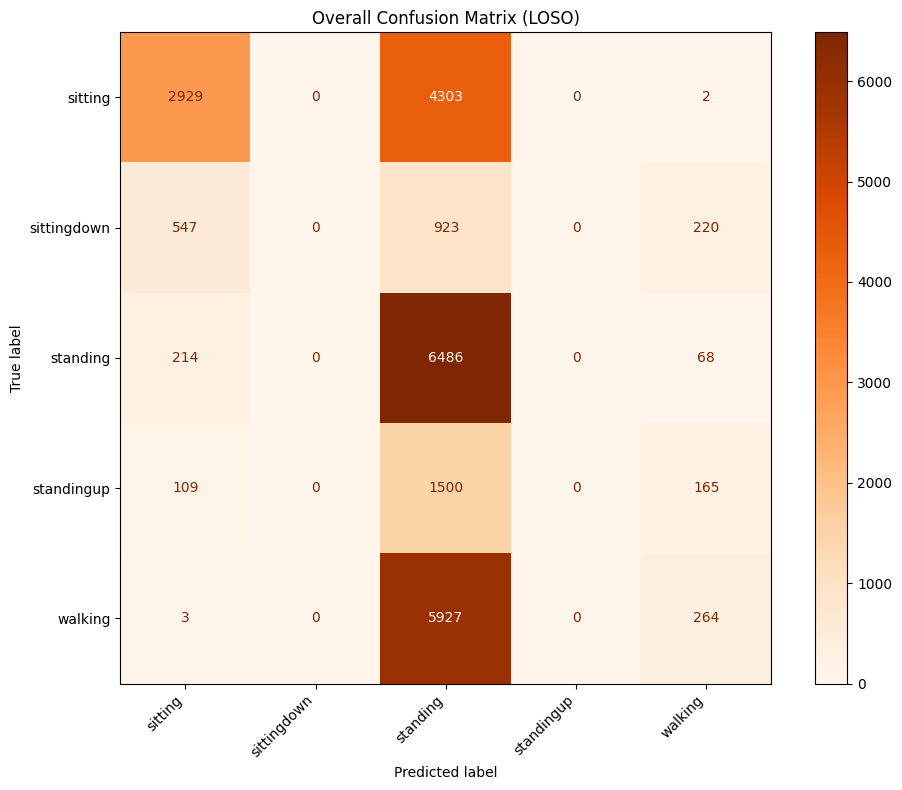

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import iqr
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

# --- 1. Preparation (Assuming windowed_df is already created as per your previous step) ---

# Get all unique classes once to ensure all confusion matrices have the same shape
all_unique_classes = sorted(windowed_df['class'].unique())

# Identify numerical features for outlier removal and discretization
features_to_process = [col for col in windowed_df.columns if col not in ['user', 'class', 'gender_Woman']]

def remove_outliers_iqr(df, columns):
    clean_df = df.copy()
    for col in columns:
        Q1 = clean_df[col].quantile(0.25)
        Q3 = clean_df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        clean_df = clean_df[(clean_df[col] >= lower_bound) & (clean_df[col] <= upper_bound)]
    return clean_df

# --- 2. LOSO Cross-Validation ---

unique_users_windowed = windowed_df['user'].unique()
f1_scores_per_user = {}
all_true_labels = []
all_predictions = []

# Initialize the overall confusion matrix with zeros, sized for ALL classes
overall_cm = np.zeros((len(all_unique_classes), len(all_unique_classes)), dtype=int)

print("Starting LOSO Cross-Validation (Fixed Confusion Matrix shape)...")

for user_id in unique_users_windowed:
    # A. Split
    train_fold = windowed_df[windowed_df['user'] != user_id].copy()
    test_fold = windowed_df[windowed_df['user'] == user_id].copy()

    if train_fold.empty or test_fold.empty:
        continue

    # B. Outlier Removal (ONLY on Training Data)
    train_fold_clean = remove_outliers_iqr(train_fold, features_to_process)

    # C. Separate X and y
    X_train = train_fold_clean.drop(columns=['user', 'class'])
    y_train = train_fold_clean['class']
    X_test = test_fold.drop(columns=['user', 'class'])
    y_test = test_fold['class']

    # D. Discretization (Fit on Train, Transform both)
    discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform', subsample=None, random_state=42)

    X_train_binned = discretizer.fit_transform(X_train[features_to_process])
    X_test_binned = discretizer.transform(X_test[features_to_process])

    X_train_final = pd.DataFrame(X_train_binned, columns=features_to_process, index=X_train.index)
    X_test_final = pd.DataFrame(X_test_binned, columns=features_to_process, index=X_test.index)

    if 'gender_Woman' in X_train.columns:
        X_train_final['gender_Woman'] = X_train['gender_Woman']
        X_test_final['gender_Woman'] = X_test['gender_Woman']

    # E. Train & Predict
    clf = DecisionTreeClassifier(random_state=42)
    clf.fit(X_train_final, y_train)
    y_pred = clf.predict(X_test_final)

    # F. Metrics
    f1 = f1_score(y_test, y_pred, average='weighted')
    f1_scores_per_user[user_id] = f1

    all_true_labels.extend(y_test)
    all_predictions.extend(y_pred)

    # G. Confusion Matrix FIX:
    # Use the 'labels' parameter to force the matrix to include all classes
    # even if they are missing for this specific user.
    cm = confusion_matrix(y_test, y_pred, labels=all_unique_classes)
    overall_cm += cm

    print(f"User {user_id} processed. F1: {f1:.4f}")

# --- 3. Final Results ---
print("\n--- LOSO Cross-Validation Results ---")
overall_f1 = f1_score(all_true_labels, all_predictions, average='weighted')
print(f"Overall F1-score: {overall_f1:.4f}")

# Display Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=overall_cm, display_labels=all_unique_classes)
disp.plot(cmap=plt.cm.Oranges, ax=ax)
ax.set_title('Overall Confusion Matrix (LOSO)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


from sklearn.neighbors import LocalOutlierFactor

# --- LOSO with Local Outlier Factor (LOF) ---

f1_scores_lof = {}
all_true_lof = []
all_pred_lof = []
overall_cm_lof = np.zeros((len(all_unique_classes), len(all_unique_classes)), dtype=int)

print("Starting LOSO with LOF Outlier Detection...")

for user_id in unique_users_windowed:
    # A. Split
    train_fold = windowed_df[windowed_df['user'] != user_id].copy()
    test_fold = windowed_df[windowed_df['user'] == user_id].copy()
    
    if train_fold.empty or test_fold.empty:
        continue

    # B. LOF Outlier Removal (ONLY on Training Data)
    # contamination is the expected proportion of outliers (e.g., 5%)
    lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
    # Predict -1 for outliers and 1 for inliers
    outlier_labels = lof.fit_predict(train_fold[features_to_process])
    train_fold_clean = train_fold[outlier_labels == 1]

    # C. Separate X and y
    X_train = train_fold_clean.drop(columns=['user', 'class'])
    y_train = train_fold_clean['class']
    X_test = test_fold.drop(columns=['user', 'class'])
    y_test = test_fold['class']

    # D. Discretization
    discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform', subsample=None, random_state=42)
    X_train_final = pd.DataFrame(discretizer.fit_transform(X_train[features_to_process]), 
                                 columns=features_to_process, index=X_train.index)
    X_test_final = pd.DataFrame(discretizer.transform(X_test[features_to_process]), 
                                columns=features_to_process, index=X_test.index)

    if 'gender_Woman' in X_train.columns:
        X_train_final['gender_Woman'] = X_train['gender_Woman']
        X_test_final['gender_Woman'] = X_test['gender_Woman']

    # E. Train & Predict
    clf = DecisionTreeClassifier(random_state=42)
    clf.fit(X_train_final, y_train)
    y_pred = clf.predict(X_test_final)

    # F. Metrics
    f1_scores_lof[user_id] = f1_score(y_test, y_pred, average='weighted')
    all_true_lof.extend(y_test)
    all_pred_lof.extend(y_pred)
    overall_cm_lof += confusion_matrix(y_test, y_pred, labels=all_unique_classes)

print(f"LOF - Overall F1-score: {f1_score(all_true_lof, all_pred_lof, average='weighted'):.4f}")

### 10) STATISTICAL COMPARISON

Running 10000 bootstrap iterations to find the best model...


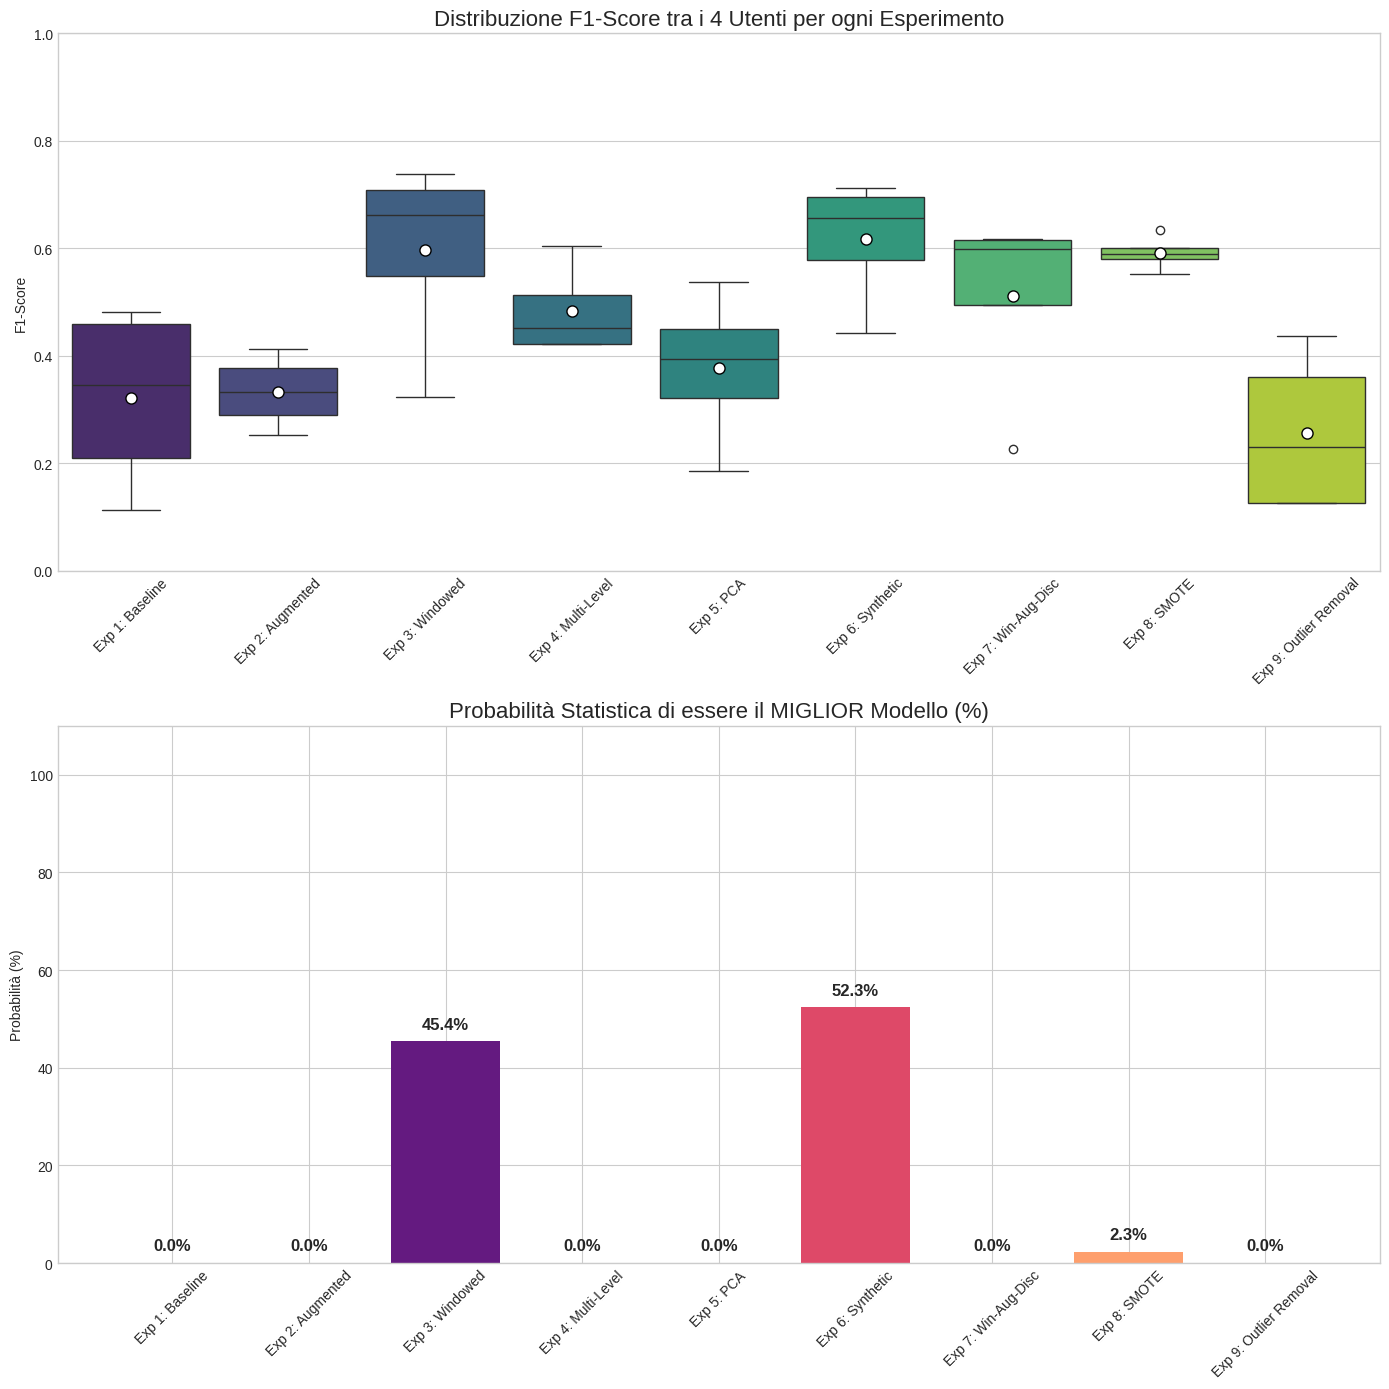


--- RANKING STATISTICO FINALE ---
 1. Exp 6: Synthetic     | Mean F1: 0.6164 | Prob. di essere Best:  52.3%
 2. Exp 3: Windowed      | Mean F1: 0.5961 | Prob. di essere Best:  45.4%
 3. Exp 8: SMOTE         | Mean F1: 0.5914 | Prob. di essere Best:   2.3%
 4. Exp 7: Win-Aug-Disc  | Mean F1: 0.5102 | Prob. di essere Best:   0.0%
 5. Exp 4: Multi-Level   | Mean F1: 0.4822 | Prob. di essere Best:   0.0%
 6. Exp 5: PCA           | Mean F1: 0.3774 | Prob. di essere Best:   0.0%
 7. Exp 2: Augmented     | Mean F1: 0.3327 | Prob. di essere Best:   0.0%
 8. Exp 1: Baseline      | Mean F1: 0.3216 | Prob. di essere Best:   0.0%
 9. Exp 9: Outlier Removal | Mean F1: 0.2555 | Prob. di essere Best:   0.0%


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. DATA COLLECTION (Hardcoded dai tuoi log per evitare sovrascritture)
# Gli utenti devono essere nello stesso ordine per tutti i dizionari
users = ["debora", "jose_carlos", "katia", "wallace"]

results_map = {
    "Exp 1: Baseline":        [0.4819, 0.1122, 0.4513, 0.2410],
    "Exp 2: Augmented":       [0.3012, 0.2515, 0.4131, 0.3652],
    "Exp 3: Windowed":        [0.7390, 0.3222, 0.6991, 0.6241],
    "Exp 4: Multi-Level":     [0.4208, 0.6039, 0.4818, 0.4223],
    "Exp 5: PCA":             [0.5369, 0.3670, 0.1847, 0.4210],
    "Exp 6: Synthetic":       [0.4413, 0.7113, 0.6230, 0.6900],
    "Exp 7: Win-Aug-Disc":    [0.6139, 0.2255, 0.5840, 0.6174],
    "Exp 8: SMOTE":           [0.5898, 0.5902, 0.5518, 0.6337],
    "Exp 9: Outlier Removal":[0.4360, 0.1252, 0.3360, 0.1250]
}

# Creazione DataFrame: righe = utenti, colonne = esperimenti
df_results = pd.DataFrame(results_map, index=users)

# 2. BOOTSTRAP SIMULATION
n_iterations = 10000
winners = []

print(f"Running {n_iterations} bootstrap iterations to find the best model...")

# Impostiamo un seed per la riproducibilità
np.random.seed(42)

for _ in range(n_iterations):
    # Resample degli utenti con rimpiazzo (bootstrap sulle righe)
    bootstrap_sample = df_results.sample(n=len(df_results), replace=True)
    # Calcolo media F1 per ogni esperimento in questo campione
    means = bootstrap_sample.mean()
    # Identifica quale esperimento ha vinto in questa iterazione
    winners.append(means.idxmax())

# 3. PROBABILITY CALCULATION
prob_best = pd.Series(winners).value_counts(normalize=True).reindex(df_results.columns, fill_value=0) * 100

# 4. VISUALIZATION
plt.style.use('seaborn-v0_8-whitegrid') # Stile grafico pulito
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 14))

# Plot 1: Boxplot of F1-Scores (Distribuzione reale sui 4 utenti)
sns.boxplot(data=df_results, ax=ax1, palette="viridis", showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"})
ax1.set_title('Distribuzione F1-Score tra i 4 Utenti per ogni Esperimento', fontsize=16)
ax1.set_ylabel('F1-Score')
ax1.tick_params(axis='x', rotation=45)
ax1.set_ylim(0, 1)

# Plot 2: Probability of being the Best (Risultato Bootstrap)
colors = sns.color_palette("magma", len(prob_best))
bars = ax2.bar(prob_best.index, prob_best.values, color=colors)
ax2.set_title('Probabilità Statistica di essere il MIGLIOR Modello (%)', fontsize=16)
ax2.set_ylabel('Probabilità (%)')
ax2.set_ylim(0, 110)
ax2.tick_params(axis='x', rotation=45)

# Aggiunta etichette sopra le barre
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 2,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

# 5. FINAL STATISTICAL RANKING
print("\n" + "="*50)
print("--- RANKING STATISTICO FINALE ---")
print("="*50)
ranking = df_results.mean().sort_values(ascending=False)
for i, (name, score) in enumerate(ranking.items(), 1):
    best_p = prob_best[name]
    print(f"{i:2d}. {name:20s} | Mean F1: {score:.4f} | Prob. di essere Best: {best_p:5.1f}%")